# Лабораторная 11. Свои слои и CNN для CIFAR-10

Срок сдачи — 21 ноября 2026 года. Девять обязательных задач дают 10 баллов: BatchNorm — 2 балла, остальные — по 1. Два бонуса по +1 баллу: свёртка с одним циклом и без циклов. По правилам курса итоговая оценка ограничена 11 баллами.

Нужно реализовать свёртку на NumPy, MaxPool2d, Dropout и BatchNorm2d; собрать из своих модулей сеть PyTorch и обучить её на CIFAR-10. Затем сравнить MLP, CNN и ту же CNN с аугментациями по качеству, времени, числу параметров и устойчивости.

Свёртка NumPy выполняет только forward. В обучаемой CNN используют `nn.Conv2d`, чтобы сохранить вычисление градиентов PyTorch. Pooling, нормализация и Dropout в CNN — ваши. Для них производные вычисляет autograd по написанным тензорным операциям; собственный `backward` не требуется.

Во время реализации своих слоёв нельзя вызывать готовые аналоги `nn.MaxPool2d`, `nn.Dropout`, `nn.BatchNorm2d` и соответствующие функции `torch.nn.functional`. В открытых проверках готовые слои используются как эталон. `train()` и `eval()` наследуются от `nn.Module`; `forward` учитывает `self.training`, где это необходимо. NumPy-свёртка и MaxPool не имеют случайности или накопленных статистик, их вычисления от режима не зависят.

Типы, формы и имена в заготовках — часть контракта. Закрытые проверки используют другие данные, режимы и параметры. Абсолютная скорость компьютера и положительный выигрыш аугментаций не являются условиями оценки. Для работы нужна подпапка `support/` из комплекта занятия.

In [1]:
import copy
import json
import os
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.transforms import v2

from support.week11_utils import (
    CLASSES, ImageDataset, benchmark_inference, channel_statistics,
    choose_device, classification_metrics, corrupt_images, evaluate_model,
    load_data, make_loader, paired_accuracy_interval, parameter_count,
    plot_comparison, plot_histories, plot_robustness, predict_probabilities,
    seed_everything, show_class_metrics, show_images, show_table, synchronize,
)

SEED = 42
seed_everything(SEED)
torch.set_num_threads(4)
DEVICE = choose_device()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("torch", torch.__version__, "device", DEVICE, "platform", platform.platform())

from support.lesson11_visuals import setup_style
setup_style()

torch 2.15.0+cu132 device cuda platform Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.39


In [2]:
from support.week11_utils import draw_matrices, draw_pipeline, plot_metric_panels

In [3]:
a = np.array([[
    [[1,2],
     [3,4]], 
    [[5,6],
     [7,8]],
    [[9,10],
     [11,12]]
     ]])

print(a.shape)
print(np.pad(a, ((0,0), (0,0), (1,1), (1,1))).shape)

(1, 3, 2, 2)
(1, 3, 4, 4)


## NumPy-свёртка: общий контракт

Каждая функция получает X формы N×C_in×H×W, ядра K формы C_out×C_in×k_h×k_w и необязательный bias формы C_out. Типы float32 или float64, вход и веса одного типа. Вернуть массив N×C_out×H_out×W_out того же типа. Ядра не переворачивают, dilation=1, groups=1.

$$Y_{n,o,i,j}=b_o+\sum_c\sum_u\sum_vK_{o,c,u,v}X^{pad}_{n,c,is+u,js+v}.$$

Размеры выхода: $H_{out}=\lfloor(H+2p-k_h)/s\rfloor+1$, аналогично W. Нулевое дополнение p≥0, целый stride s≥1; формы корректны, выход непустой. Входы и веса изменять нельзя.

Четыре функции имеют один контракт и вычисляют одну операцию; меняется организация вычислений. Нельзя вызывать готовые свёртки PyTorch, SciPy или OpenCV внутри реализации. Число циклов относится к явным Python-циклам в функции и её вспомогательных функциях; генераторы, comprehensions, `np.vectorize` и `frompyfunc` не служат обходом ограничения.

Каналы и выходные ядра во всех версиях обрабатывают векторно. Основная часть требует версии с тремя и двумя вложенными циклами. Бонусные версии можно не выполнять: их незаполненные заготовки не прерывают обязательные эксперименты.

## Задача 1. Свёртка: три вложенных цикла — 1 балл

Три вложенных цикла: по объектам N, строкам H_out и столбцам W_out. Внутри одного положения вычисляют сразу все выходные каналы.

In [4]:
def conv2d_three_loops(images: np.ndarray, weights: np.ndarray, bias: np.ndarray | None=None, stride: int=1, padding: int=0) -> np.ndarray:
    N, C_in, H, W = images.shape
    C_out, _, k_h, k_w = weights.shape
    H_out = (H + 2 * padding - k_h) // stride + 1
    W_out = (W + 2 * padding - k_w) // stride + 1
    padded = np.pad(images, ((0,0), (0,0), (padding, padding), (padding, padding)))
    out = np.zeros((N, C_out, H_out, W_out))
    for image in range(N):
        for i in range(H_out):
            for j in range(W_out):
                patch = padded[image, :, i * stride:i * stride + k_h, j * stride:j * stride + k_w]
                value = np.sum(weights * patch[None, :, :, :], axis=(1, 2, 3))
                if bias is not None:
                    value = value + bias
                out[image, :, i, j] = value
    return out

In [5]:
rng = np.random.default_rng(11)
conv_images = rng.normal(size=(2, 3, 4, 5))
conv_weights = rng.normal(size=(4, 3, 2, 3))
conv_bias = rng.normal(size=4)
conv_result = conv2d_three_loops(conv_images, conv_weights, conv_bias, stride=2, padding=1)
conv_reference = nn.functional.conv2d(torch.tensor(conv_images), torch.tensor(conv_weights),
                                     torch.tensor(conv_bias), stride=2, padding=1).numpy()
assert conv_result.shape == (2, 4, 3, 3)
assert np.allclose(conv_result, conv_reference)
print("conv2d_three_loops: результат совпадает с эталоном")

conv2d_three_loops: результат совпадает с эталоном


## Задача 2. Свёртка: два вложенных цикла — 1 балл

Два вложенных цикла: только по строкам и столбцам выхода. Все объекты батча и выходные каналы в одном положении обрабатывают векторно.

In [6]:
def conv2d_two_loops(images: np.ndarray, weights: np.ndarray, bias: np.ndarray | None=None, stride: int=1, padding: int=0) -> np.ndarray:
    N, C_in, H, W = images.shape
    C_out, _, k_h, k_w = weights.shape
    H_out = (H + 2 * padding - k_h) // stride + 1
    W_out = (W + 2 * padding - k_w) // stride + 1
    padded = np.pad(images, ((0,0), (0,0), (padding, padding), (padding, padding)))
    out = np.zeros((N, C_out, H_out, W_out))
    kernel_matrix = weights.reshape(C_out, -1)
    for i in range(H_out):
        for j in range(W_out):
            patch = padded[:, :, i * stride:i * stride + k_h, j * stride:j * stride + k_w]
            if bias is None:
                bias = 0
            out[:, :, i, j] = patch.reshape(N, -1) @ kernel_matrix.T + bias
    return out

In [7]:
rng = np.random.default_rng(11)
conv_images = rng.normal(size=(2, 3, 4, 5))
conv_weights = rng.normal(size=(4, 3, 2, 3))
conv_bias = rng.normal(size=4)
conv_result = conv2d_two_loops(conv_images, conv_weights, conv_bias, stride=2, padding=1)
conv_reference = nn.functional.conv2d(torch.tensor(conv_images), torch.tensor(conv_weights),
                                     torch.tensor(conv_bias), stride=2, padding=1).numpy()
assert conv_result.shape == (2, 4, 3, 3)
assert np.allclose(conv_result, conv_reference)
print("conv2d_two_loops: результат совпадает с эталоном")

conv2d_two_loops: результат совпадает с эталоном


## Бонус 1. Свёртка: один цикл — +1 балл

Один цикл по изображениям батча. Все пространственные положения и выходные каналы одного изображения вычисляют векторно.

In [8]:
def conv2d_one_loop(images: np.ndarray, weights: np.ndarray, bias: np.ndarray | None=None, stride: int=1, padding: int=0) -> np.ndarray:
    ...

In [9]:
bonus_result = conv2d_one_loop(conv_images, conv_weights, conv_bias, stride=2, padding=1)
if bonus_result is None:
    print("Бонус 1: заготовка пока не заполнена")
else:
    assert bonus_result.shape == conv_reference.shape
    assert np.allclose(bonus_result, conv_reference)
    print("conv2d_one_loop: результат совпадает с эталоном")

Бонус 1: заготовка пока не заполнена


## Бонус 2. Свёртка без циклов — +1 балл

Ни одного явного Python-цикла. Батч, пространственные положения и выходные каналы обрабатывают векторными операциями NumPy. Дополнительные библиотеки и готовые свёртки не используют.

In [10]:
def conv2d_no_loops(images: np.ndarray, weights: np.ndarray, bias: np.ndarray | None=None, stride: int=1, padding: int=0) -> np.ndarray:
    ...

In [11]:
bonus_result = conv2d_no_loops(conv_images, conv_weights, conv_bias, stride=2, padding=1)
if bonus_result is None:
    print("Бонус 2: заготовка пока не заполнена")
else:
    assert bonus_result.shape == conv_reference.shape
    assert np.allclose(bonus_result, conv_reference)
    print("conv2d_no_loops: результат совпадает с эталоном")

Бонус 2: заготовка пока не заполнена


### Сравнение одинаковых реализаций

Ниже одинаковые вход, ядра и dtype. Перед измерением проверяют совпадение результатов, затем прогревают функции и берут медиану пяти запусков. Незавершённые бонусы пропускаются. Число Python-циклов само по себе не определяет скорость: важны временные массивы, порядок памяти и стоимость вызовов векторных операций. По результату сравните время и ускорение относительно версии с тремя циклами.

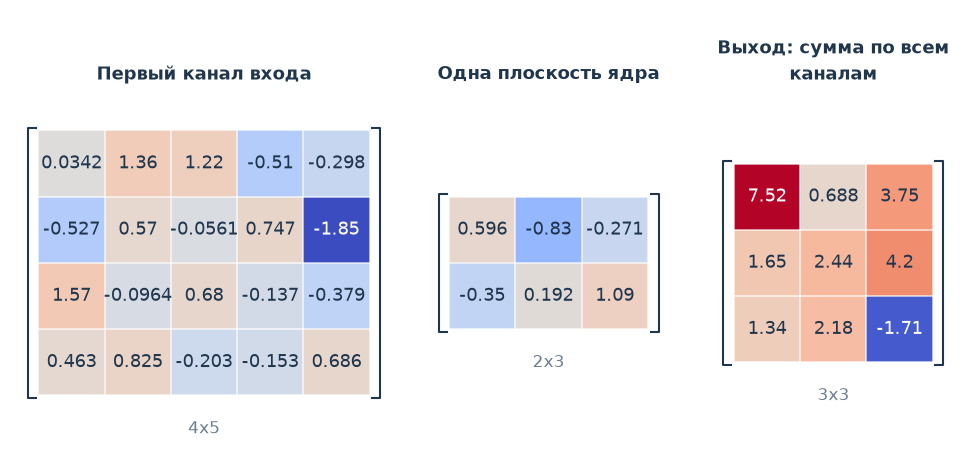

,"Медиана, мс",Ускорение к 3 циклам
Реализация,,
3 цикла,24.8423,1.0000
2 цикла,4.8747,5.0961


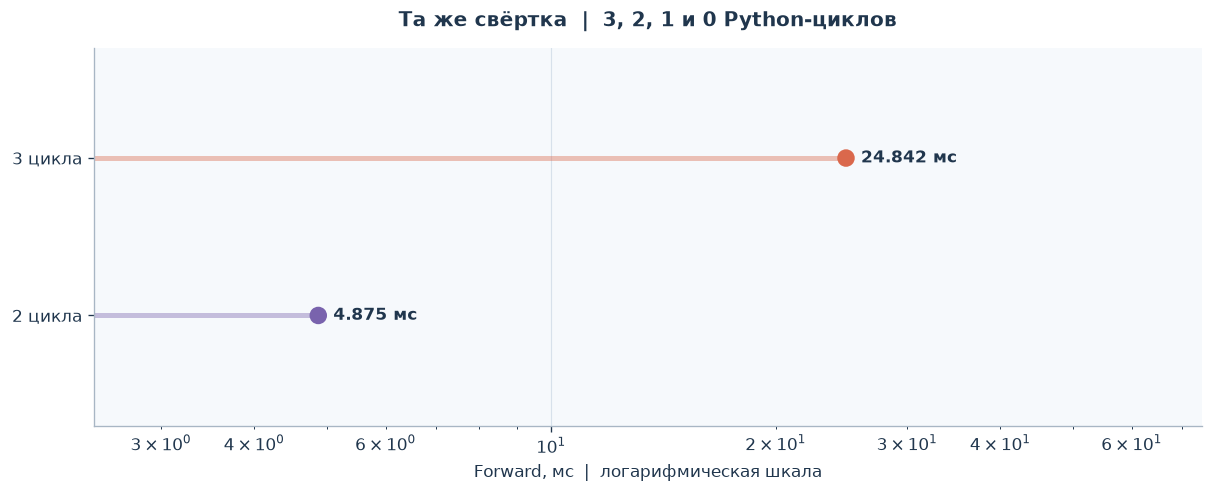

In [12]:
# Общий пример и измерения для всех заполненных версий.
draw_matrices([conv_images[0, 0], conv_weights[0, 0], conv_result[0, 0]],
              ["Первый канал входа", "Одна плоскость ядра", "Выход: сумма по всем каналам"])
speed_images = rng.normal(size=(4, 3, 32, 32)).astype(np.float32)
speed_weights = rng.normal(size=(8, 3, 3, 3)).astype(np.float32)
reference = nn.functional.conv2d(torch.from_numpy(speed_images), torch.from_numpy(speed_weights)).numpy()
implementations = [
    ("3 цикла", conv2d_three_loops), ("2 цикла", conv2d_two_loops),
    ("1 цикл  |  бонус", conv2d_one_loop), ("0 циклов  |  бонус", conv2d_no_loops),
]
speed_rows = []
for name, function in implementations:
    actual = function(speed_images, speed_weights)
    if actual is None:
        continue
    assert np.allclose(actual, reference, atol=1e-5)
    durations = []
    for repeat in range(5):
        started = time.perf_counter()
        function(speed_images, speed_weights)
        durations.append(1000 * (time.perf_counter() - started))
    speed_rows.append({"Реализация": name, "Медиана, мс": np.median(durations)})
speed_table = pd.DataFrame(speed_rows).set_index("Реализация")
speed_table["Ускорение к 3 циклам"] = speed_table.iloc[0, 0] / speed_table["Медиана, мс"]
show_table(speed_table)
figure, axis = plt.subplots(figsize=(10, 4), layout="constrained")
positions = np.arange(len(speed_table))
values = speed_table["Медиана, мс"].to_numpy()
colors = ["#da684c", "#7963ad", "#c19022", "#087f8c"][:len(values)]
axis.hlines(positions, values.min() / 2, values, color=colors, lw=3, alpha=.4)
axis.scatter(values, positions, color=colors, s=90, zorder=3)
for position, value in zip(positions, values):
    axis.annotate(f"{value:.3f} мс", (value, position), xytext=(9, 0),
                  textcoords="offset points", va="center", weight="bold")
axis.set_xscale("log")
axis.set(xlabel="Forward, мс  |  логарифмическая шкала", yticks=positions,
         yticklabels=speed_table.index, xlim=(values.min() / 2, values.max() * 3),
         ylim=(-.7, len(values) - .3), title="Та же свёртка  |  3, 2, 1 и 0 Python-циклов")
axis.invert_yaxis()
axis.grid(axis="x")
plt.show()

## Задача 3. Свой MaxPool2d — 1 балл

`ManualMaxPool2d(kernel_size, stride=None)` — модуль без параметров и буферов. Целые kernel_size≥1 и stride≥1; при stride=None шаг равен kernel_size. Вход N×C×H×W; максимум считают отдельно в каждом пространственном окне каждого канала. Padding=0, dilation=1, ceil_mode=False. Формула размера та же, что у свёртки без padding.

Выход сохраняет dtype, device и связь с autograd. Режимы train и eval дают один результат. При нескольких равных максимумах градиент получает первый элемент окна при обходе по строкам. При перекрытии окон вклады градиента складываются. Готовые pooling-функции использовать нельзя.

In [13]:
class ManualMaxPool2d(nn.Module):

    def __init__(self, kernel_size: int=2, stride: int | None=None):
        super().__init__()
        if stride is None:
            stride = kernel_size
        self.kernel_size = kernel_size
        self.stride = stride

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        N, C, H, W = images.shape
        H_out = (H - self.kernel_size) // self.stride + 1
        W_out = (W - self.kernel_size) // self.stride + 1
        rows = []
        for i in range(H_out):
            cols = []
            for j in range(W_out):
                window = images[:, :, i * self.stride : i * self.stride + self.kernel_size, j * self.stride : j * self.stride + self.kernel_size]
                window = window.reshape(N, C, self.kernel_size * self.kernel_size)
                max_values = torch.max(window, dim=2).values
                cols.append(max_values)

            rows.append(torch.stack(cols, dim=-1))

        output = torch.stack(rows, dim=-2)
        return output

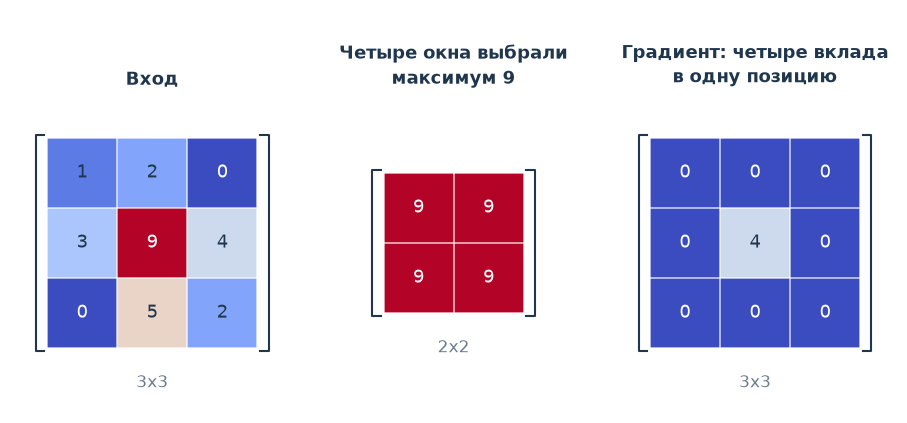

In [14]:
pool_input = torch.tensor([[[[1., 2., 0.], [3., 9., 4.], [0., 5., 2.]]]], requires_grad=True)
manual_pool = ManualMaxPool2d(2, stride=1)
pooled = manual_pool(pool_input)
assert torch.equal(pooled, nn.MaxPool2d(2, stride=1)(pool_input))
manual_pool.eval()
assert torch.equal(manual_pool(pool_input), pooled)
pooled.sum().backward()
assert pool_input.grad[0, 0, 1, 1] == 4
assert len(list(manual_pool.parameters())) == 0
draw_matrices([pool_input.detach().numpy()[0, 0], pooled.detach().numpy()[0, 0], pool_input.grad.numpy()[0, 0]],
              ["Вход", "Четыре окна выбрали максимум 9", "Градиент: четыре вклада в одну позицию"])

## Задача 4. Свой Dropout — 1 балл

`ManualDropout(p=0.5)` использует p как вероятность выключения, 0≤p≤1. В train элементы независимо обнуляются с вероятностью p, оставшиеся делятся на 1−p. Каждому новому forward соответствует новая маска. При p=1 вернуть нули без NaN; при p=0 — исходные значения.

В eval вернуть вход без изменений и без случайного отбора. Форма, dtype и device сохраняются; вход не изменяют. У слоя нет обучаемых параметров и буферов. Градиент в train умножается на ту же маску и масштаб, в eval равен входящему градиенту.

In [15]:
class ManualDropout(nn.Module):

    def __init__(self, p: float=0.5):
        super().__init__()
        self.p = p

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        if not self.training or self.p == 0.0:
            return inputs
        keep = torch.rand_like(inputs) >= self.p
        scale = 0.0 if self.p == 1.0 else 1.0 / (1.0 - self.p)
        return torch.where(keep, inputs * scale, torch.zeros_like(inputs))

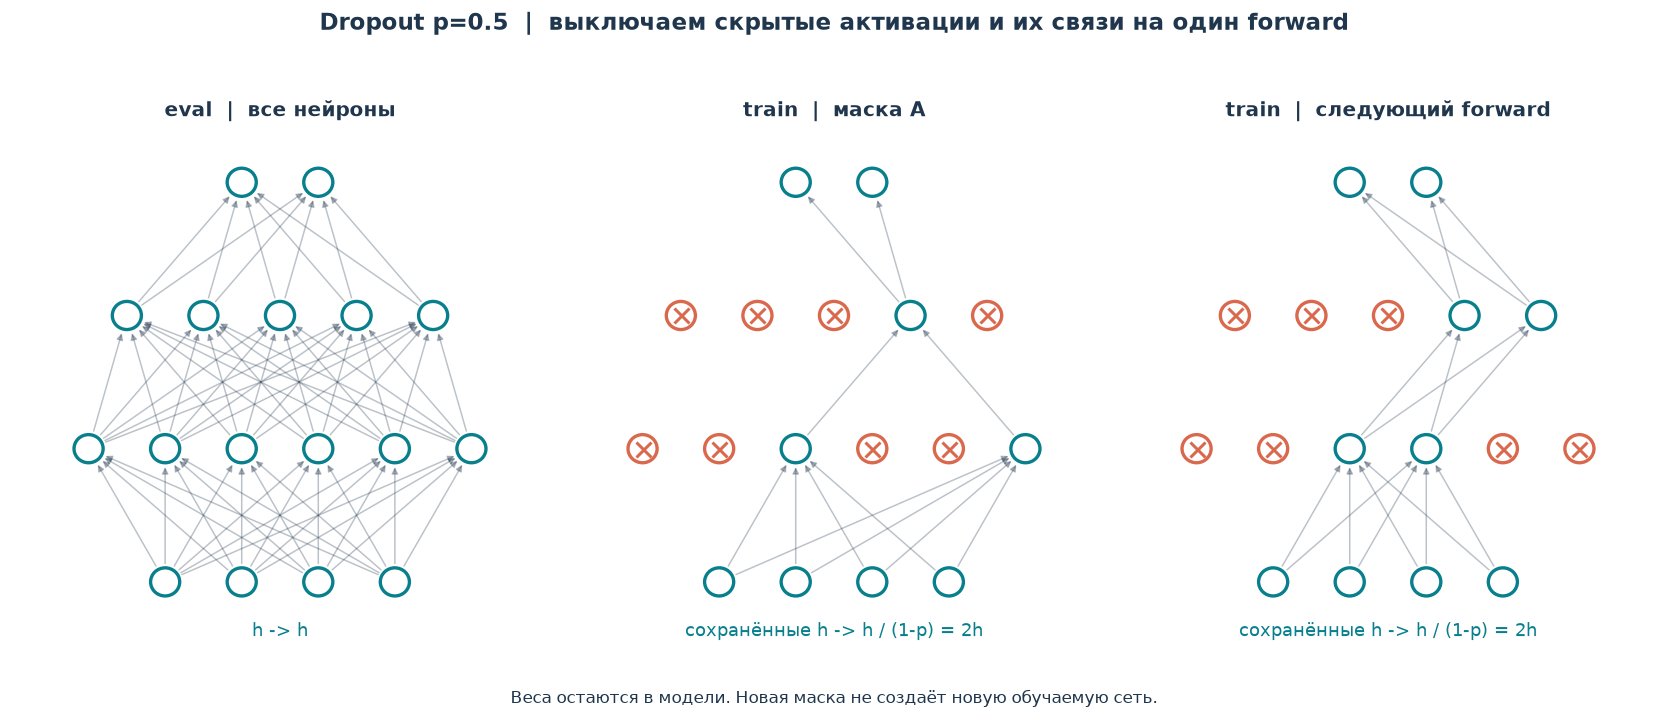

In [16]:
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(47)
    manual_dropout = ManualDropout(.5)
    drop_input = torch.ones(20000, requires_grad=True)
    dropped = manual_dropout(drop_input)
    assert torch.isin(dropped, torch.tensor([0., 2.])).all()
    assert abs(dropped.detach().mean().item() - 1) < .05
    dropped.sum().backward()
    assert torch.equal(drop_input.grad, dropped.detach())
    manual_dropout.eval()
    assert torch.equal(manual_dropout(drop_input), drop_input)
    manual_dropout.train()
    network_masks = [[manual_dropout(torch.ones(6)).numpy(), manual_dropout(torch.ones(5)).numpy()]
                     for index in range(2)]
from support.lesson11_visuals import plot_dropout_network
plot_dropout_network(network_masks, probability=.5);

## Задача 5. Свой BatchNorm2d — 2 балла

`ManualBatchNorm2d(num_features, eps=1e-5, momentum=0.1)` получает N×C×H×W, C=num_features. Два обучаемых параметра `weight` и `bias` формы C, начальные значения 1 и 0. Буферы `running_mean` и `running_var` формы C, начальные значения 0 и 1; `num_batches_tracked` — скалярный целый счётчик, начальное значение 0. Буферы регистрируют в модуле: они сохраняются в state_dict и переносятся вместе с `.to(device)`.

В train для каждого канала M=NHW значений:

$$\mu=\frac1M\sum x_i,\quad v=\frac1M\sum(x_i-\mu)^2,\quad y=\gamma\frac{x-\mu}{\sqrt{v+\varepsilon}}+\beta.$$

Обновить без записи в граф производных:

$$r_\mu\leftarrow(1-a)r_\mu+a\mu,\qquad
r_v\leftarrow(1-a)r_v+a\frac{M}{M-1}v,$$

где a=momentum; увеличить счётчик на 1. Для нормирования текущего батча используется v с делителем M, для обновления running_var — несмещённая оценка с делителем M−1. При train и M≤1 выбросить ValueError.

В eval нормировать сохранёнными running_mean/running_var, не менять буферы и счётчик. Даже один объект с одной пространственной позицией допустим. `weight` и `bias` участвуют в обоих режимах. `self.training`, а не наличие autograd, определяет режим. Обеспечить градиенты по входу, weight и bias. Предполагаются eps>0, 0<momentum≤1, affine=True, track_running_stats=True; остальные варианты реализовывать не требуется.

In [17]:
class ManualBatchNorm2d(nn.Module):

    def __init__(self, num_features: int, eps: float=1e-05, momentum: float=0.1):
        super().__init__()
        self.num_features = num_features
        self.eps = eps
        self.momentum = momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer("running_mean", torch.zeros(num_features))
        self.register_buffer("running_var", torch.ones(num_features))
        self.register_buffer("num_batches_tracked", torch.tensor(0, dtype=torch.long))

    def forward(self, inputs: torch.Tensor) -> torch.Tensor:
        channel_shape = (1, -1, 1, 1)
        if self.training:
            count = inputs.numel() // inputs.shape[1]
            if count <= 1:
                raise ValueError("в train-режиме нужно больше одного значения на канал")
            mean = inputs.mean(dim=(0, 2, 3))
            var = inputs.var(dim=(0, 2, 3), unbiased=False)
            with torch.no_grad():
                self.running_mean.mul_(1 - self.momentum).add_(self.momentum * mean)
                self.running_var.mul_(1 - self.momentum).add_(self.momentum * var * count / (count - 1))
                self.num_batches_tracked.add_(1)
        else:
            mean, var = self.running_mean, self.running_var
        normalized = (inputs - mean.reshape(channel_shape)) / torch.sqrt(var.reshape(channel_shape) + self.eps)
        return normalized * self.weight.reshape(channel_shape) + self.bias.reshape(channel_shape)

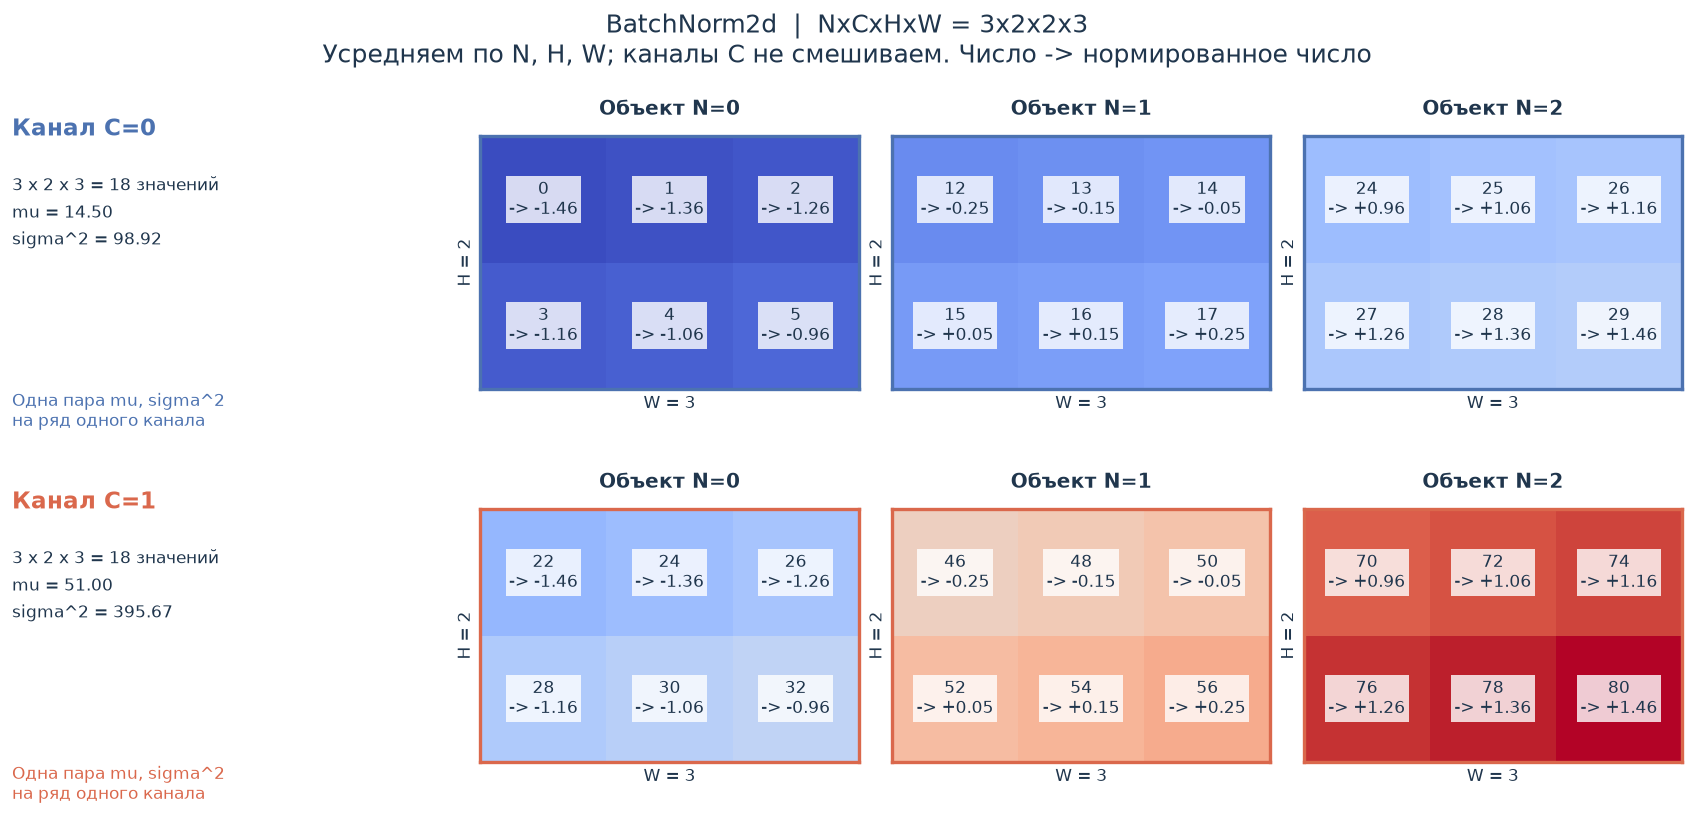

In [18]:
bn_input = torch.arange(36, dtype=torch.float64).reshape(3, 2, 2, 3)
bn_input[:, 1] = bn_input[:, 1] * 2 + 10
manual_bn = ManualBatchNorm2d(2, momentum=.2).double()
reference_bn = nn.BatchNorm2d(2, momentum=.2).double()
manual_values = manual_bn(bn_input)
reference_values = reference_bn(bn_input)
assert torch.allclose(manual_values, reference_values)
assert torch.allclose(manual_bn.running_mean, reference_bn.running_mean)
assert torch.allclose(manual_bn.running_var, reference_bn.running_var)
assert manual_bn.num_batches_tracked.item() == 1
saved_buffers = {name: value.clone() for name, value in manual_bn.named_buffers()}
manual_bn.eval()
reference_bn.eval()
assert torch.allclose(manual_bn(bn_input), reference_bn(bn_input))
assert all(torch.equal(value, saved_buffers[name]) for name, value in manual_bn.named_buffers())
from support.lesson11_visuals import plot_bn_tensor
plot_bn_tensor(bn_input.numpy(), manual_values.detach().numpy());

## Данные и протокол

Учебный режим: 12 000 train, 2 000 validation, 2 000 test, 8 эпох, батч 128.
Полный режим `W11_FULL=1`: 45 000 / 5 000 / 10 000 и 20 эпох.
Нельзя менять разбиение между моделями или выбирать эпоху по test.
Средние и стандартные отклонения RGB считают только по train.
Картинки нормализуют после перевода uint8 в float32 [0,1].

In [19]:
# Учебный режим; полный: W11_FULL=1 (45000 / 5000 / 10000, 20 эпох).
FULL = os.environ.get("W11_FULL", "0") == "1"
TRAIN_SIZE = int(os.environ.get("W11_TRAIN_SIZE", 45000 if FULL else 12000))
VAL_SIZE = int(os.environ.get("W11_VAL_SIZE", 5000 if FULL else 2000))
TEST_SIZE = int(os.environ.get("W11_TEST_SIZE", 10000 if FULL else 2000))
EPOCHS = int(os.environ.get("W11_EPOCHS", 20 if FULL else 8))
BATCH_SIZE = 128

data = load_data(TRAIN_SIZE, VAL_SIZE, TEST_SIZE, seed=SEED)
mean, std = channel_statistics(data["train_images"])
train_dataset = ImageDataset(data["train_images"], data["train_labels"], mean, std)
val_dataset = ImageDataset(data["val_images"], data["val_labels"], mean, std)
test_dataset = ImageDataset(data["test_images"], data["test_labels"], mean, std)
val_loader = make_loader(val_dataset)
test_loader = make_loader(test_dataset)

print("train / validation / test:", TRAIN_SIZE, VAL_SIZE, TEST_SIZE)
print("средние RGB:", mean, "стандартные отклонения:", std)
assert len(np.intersect1d(data["train_indices"], data["val_indices"])) == 0

train / validation / test: 12000 2000 2000
средние RGB: [0.4942917  0.48431733 0.44901112] стандартные отклонения: [0.24465628 0.24104002 0.25978625]


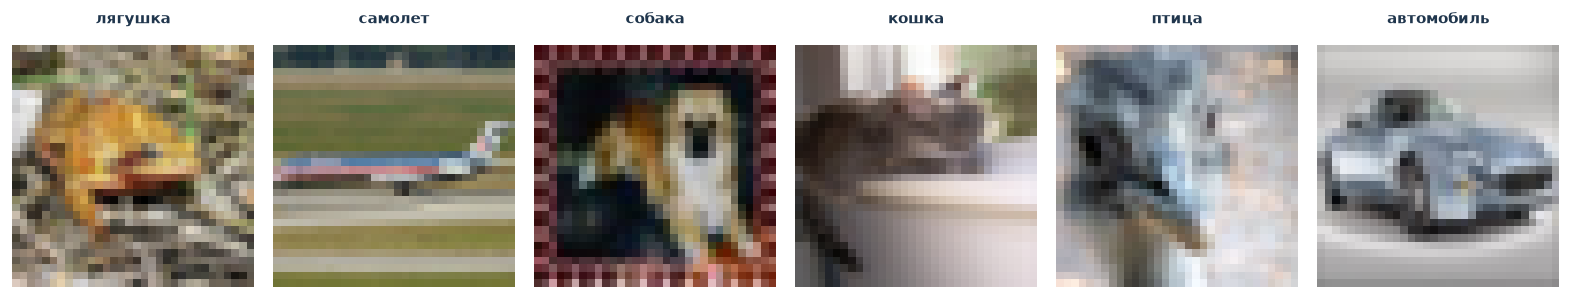

In [20]:
show_images(data["train_images"][:6], [CLASSES[y] for y in data["train_labels"][:6]])

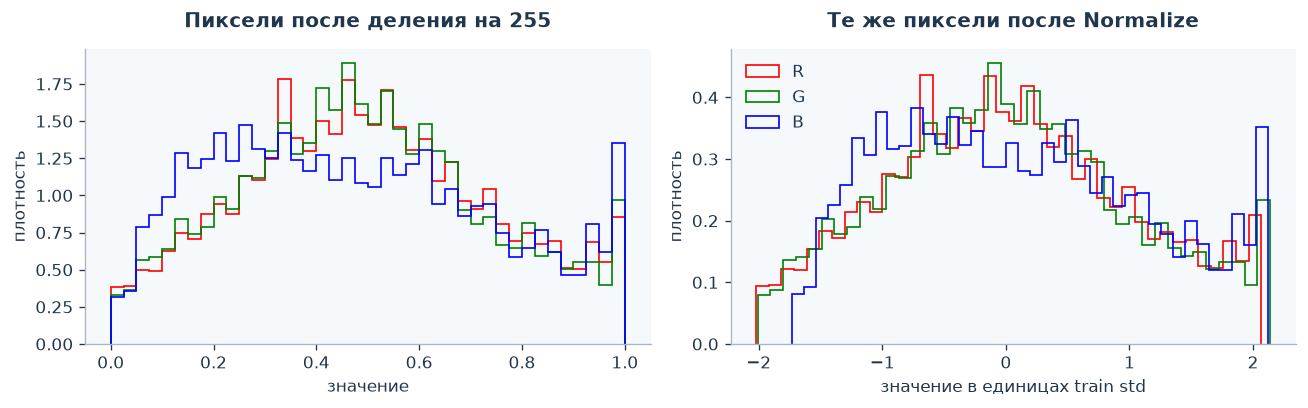

In [21]:
# Гистограммы до и после нормализации, статистики получены только на train.
example_rgb = data["train_images"][:128].astype(np.float32) / 255
standardized_rgb = (example_rgb - mean[None, None, None, :]) / std[None, None, None, :]
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for channel, color in enumerate(["red", "green", "blue"]):
    axes[0].hist(example_rgb[:, :, :, channel].reshape(-1), bins=40, histtype="step", density=True, color=color)
    axes[1].hist(standardized_rgb[:, :, :, channel].reshape(-1), bins=40, histtype="step", density=True, color=color, label=["R", "G", "B"][channel])
axes[0].set(title="Пиксели после деления на 255", xlabel="значение", ylabel="плотность")
axes[1].set(title="Те же пиксели после Normalize", xlabel="значение в единицах train std", ylabel="плотность")
axes[1].legend()
figure.tight_layout()
plt.show()

## Задача 6. CNN из собственных модулей — 1 балл

`ConvNet(batch_norm=True, dropout=0.2)` возвращает logits B×10 без softmax. Атрибуты `features` и `head` — nn.Sequential. Во всех Conv2d kernel_size=3, padding=1, bias=True.

- features: Conv2d(3,16) → [ManualBatchNorm2d(16)] → ReLU → ManualMaxPool2d(2) → Conv2d(16,32) → [ManualBatchNorm2d(32)] → ReLU → ManualMaxPool2d(2) → Conv2d(32,64) → ReLU;
- head: AdaptiveAvgPool2d((4,4)) → Flatten → Linear(1024,128) → ReLU → ManualDropout(dropout) → Linear(128,10).

BatchNorm включают только при batch_norm=True. MaxPool и Dropout — собственные реализации при всех настройках. `model.train()`/`model.eval()` должны переключать все вложенные модули. Готовый AdaptiveAvgPool2d оставлен в голове, чтобы сосредоточить ручную реализацию на MaxPool. Не переносить вычисления в NumPy внутри forward.

In [22]:
class ConvNet(nn.Module):

    def __init__(self, batch_norm: bool=True, dropout: float=0.2):
        super().__init__()
        features = [nn.Conv2d(3, 16, kernel_size=3, padding=1)]
        if batch_norm:
            features.append(ManualBatchNorm2d(16))
        features += [nn.ReLU(), ManualMaxPool2d(2), nn.Conv2d(16, 32, kernel_size=3, padding=1)]
        if batch_norm:
            features.append(ManualBatchNorm2d(32))
        features += [nn.ReLU(), ManualMaxPool2d(2), nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU()]
        self.features = nn.Sequential(*features)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128), nn.ReLU(), ManualDropout(dropout),
            nn.Linear(128, 10),
        )

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        return self.head(self.features(images))

In [23]:
probe = ConvNet()
probe_output = probe(torch.zeros(3, 3, 32, 32))
assert probe_output.shape == (3, 10)
probe.eval()
assert all(not layer.training for layer in probe.modules())
probe.train()
assert all(layer.training for layer in probe.modules())
print("Параметры:", parameter_count(probe))
print(probe)

Параметры: 156170
ConvNet(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ManualBatchNorm2d()
    (2): ReLU()
    (3): ManualMaxPool2d()
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ManualBatchNorm2d()
    (6): ReLU()
    (7): ManualMaxPool2d()
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
  )
  (head): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(4, 4))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=1024, out_features=128, bias=True)
    (3): ReLU()
    (4): ManualDropout()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)


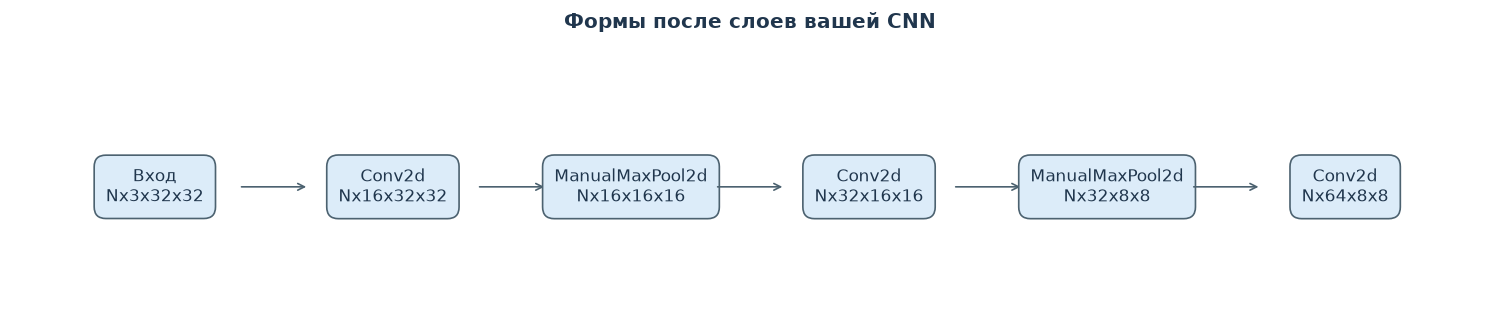

In [24]:
# Визуальная проверка структуры использует именно написанную модель probe.
probe_input = torch.zeros(1, 3, 32, 32)
probe_labels = ["Вход\nNx3x32x32"]
probe_values = probe_input
for index, layer in enumerate(probe.features):
    probe_values = layer(probe_values)
    if isinstance(layer, nn.Conv2d) or isinstance(layer, ManualMaxPool2d):
        probe_labels.append(f"{type(layer).__name__}\nNx" + "x".join(map(str, probe_values.shape[1:])))
draw_pipeline(probe_labels, "Формы после слоев вашей CNN")

## Задача 7. Одна эпоха обучения — 1 балл

Реализовать `train_epoch`: перевести модель в train-режим, выполнить обучение на всех
батчах и вернуть среднюю кросс-энтропию за эпоху. Среднее взвешивают количеством
объектов, включая последний неполный батч. Градиенты между батчами не накапливают.
Используют переданный оптимизатор; новую модель или оптимизатор внутри не создают.
Вход модели может иметь любую форму после батчевой оси: закрытая проверка использует
малую линейную сеть вместо CNN. DataLoader всегда непустой.

In [25]:
def train_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer, device: torch.device) -> float:
    model.train()
    criterion = nn.CrossEntropyLoss()
    loss_sum = 0.0
    count = 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(labels)
        count += len(labels)
    return float(loss_sum / count)

In [26]:
seed_everything(SEED)
toy_model = nn.Linear(4, 10)
toy_dataset = TensorDataset(torch.randn(7, 4), torch.arange(7))
toy_loader = DataLoader(toy_dataset, batch_size=3, shuffle=False)
toy_optimizer = torch.optim.SGD(toy_model.parameters(), lr=0.02)
old_weights = toy_model.weight.detach().clone()
toy_loss = train_epoch(toy_model, toy_loader, toy_optimizer, torch.device("cpu"))
assert isinstance(toy_loss, float) and np.isfinite(toy_loss)
assert not torch.equal(old_weights, toy_model.weight)
print("Средний loss:", toy_loss)

Средний loss: 2.172691379274641


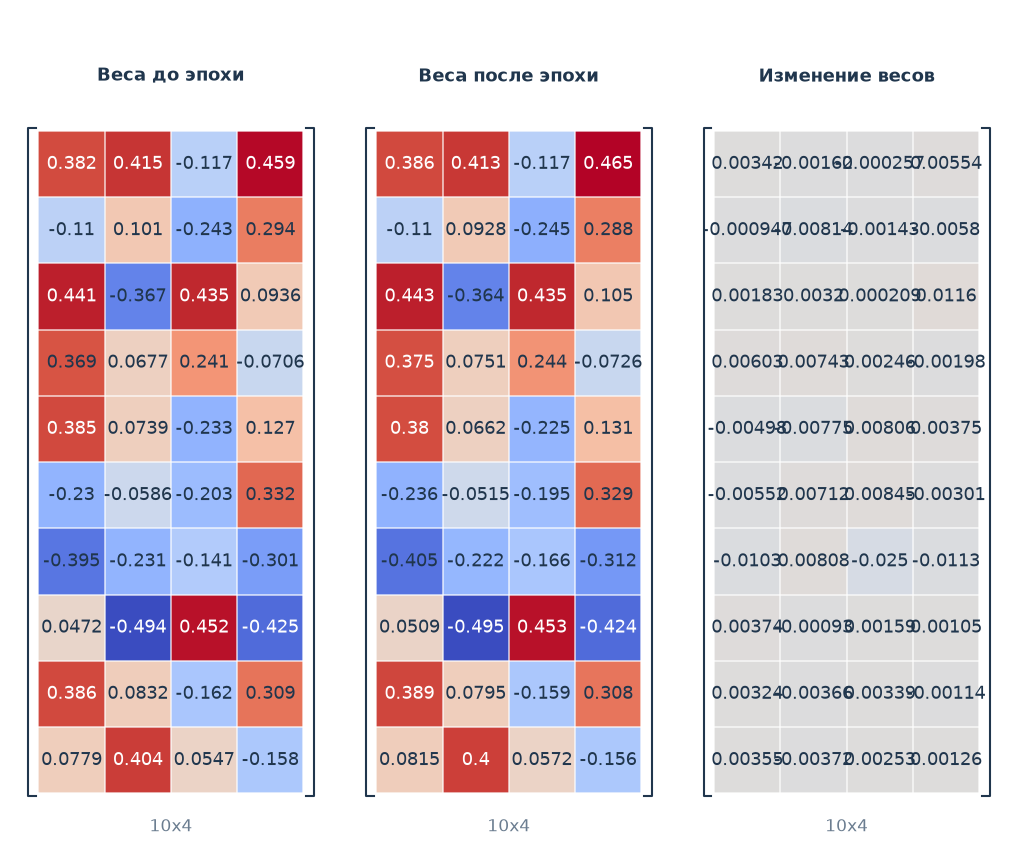

In [27]:
# Сравнивают состояние весов до и после вызова train_epoch из открытой проверки.
weight_change = (toy_model.weight.detach() - old_weights).numpy()
draw_matrices([old_weights.numpy(), toy_model.weight.detach().numpy(), weight_change],
              ["Веса до эпохи", "Веса после эпохи", "Изменение весов"])

## Задача 8. Качество классификации — 1 балл

Вернуть `accuracy`, `macro_f1`, `log_loss` по меткам и вероятностям десяти классов.
Macro-F1 усредняют по **всем десяти классам**, нулевые знаменатели дают ноль.
Для log loss используют натуральный логарифм. Разрешен sklearn.
Входные строки — распределения вероятностей; отдельные вероятности могут быть нулевыми.
Используют стандартное численное ограничение sklearn для log loss.

In [28]:
from sklearn.metrics import accuracy_score, f1_score, log_loss

def quality_metrics(labels: np.ndarray, probabilities: np.ndarray) -> dict[str, float]:
    labels = np.asarray(labels).reshape(-1)
    probabilities = np.asarray(probabilities)
    classes = np.arange(10)
    predicted = probabilities.argmax(axis=1)
    return {
        "accuracy": float(accuracy_score(labels, predicted)),
        # labels=classes: усреднение по всем десяти классам, пустой знаменатель даёт 0.
        "macro_f1": float(f1_score(labels, predicted, labels=classes, average="macro", zero_division=0)),
        "log_loss": float(log_loss(labels, probabilities, labels=classes)),
    }

In [29]:
metric_labels = np.arange(10)
metric_probabilities = np.eye(10) * 0.9 + 0.01
metric_result = quality_metrics(metric_labels, metric_probabilities)
assert np.isclose(metric_result["accuracy"], 1)
assert np.isclose(metric_result["macro_f1"], 1)
assert np.isclose(metric_result["log_loss"], -np.log(0.91))
show_table(pd.DataFrame([metric_result]))

,accuracy,macro_f1,log_loss
0,1.0000,1.0000,0.0943


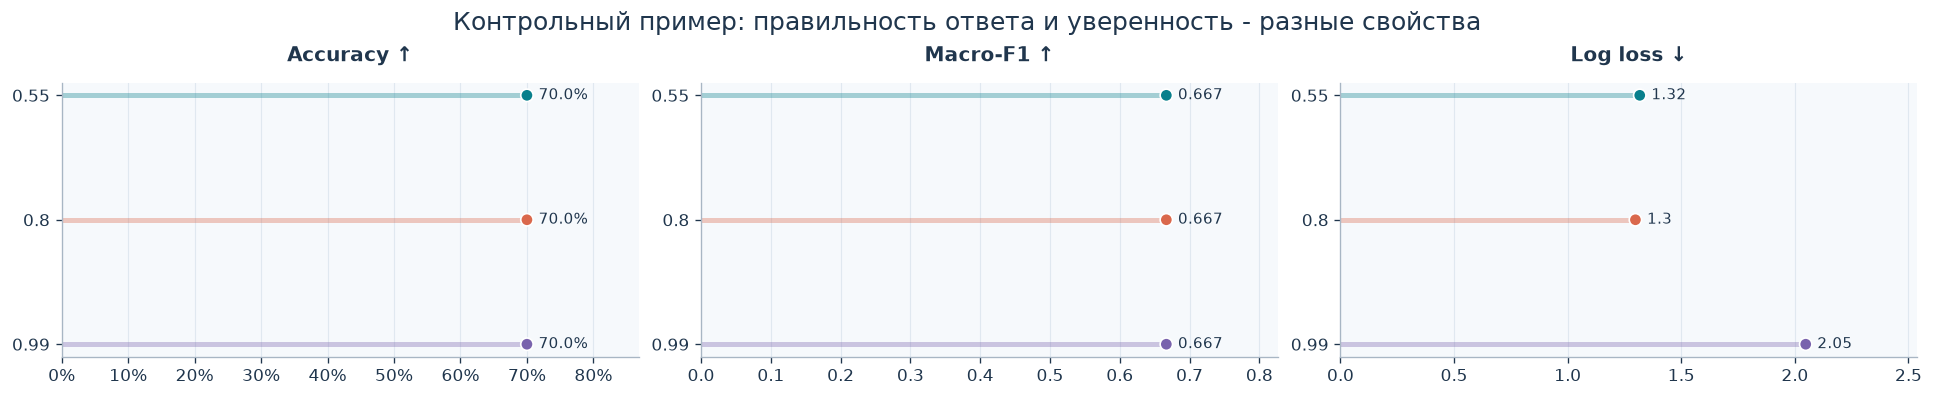

In [30]:
# Один и тот же набор ошибок: меняют только уверенность ответа.
confidence_rows = []
for confidence in [0.55, 0.8, 0.99]:
    probabilities = np.full((10, 10), (1 - confidence) / 9)
    predicted = np.arange(10)
    predicted[:3] = [1, 2, 3]
    probabilities[np.arange(10), predicted] = confidence
    metrics = quality_metrics(np.arange(10), probabilities)
    confidence_rows.append({"уверенность": str(confidence), **metrics})
confidence_table = pd.DataFrame(confidence_rows).set_index("уверенность")
plot_metric_panels(confidence_table, columns=["accuracy", "macro_f1", "log_loss"],
                   title="Контрольный пример: правильность ответа и уверенность - разные свойства")

## Готовое измерение задержки

Ниже реализовано измерение медианы времени одного прямого прохода, миллисекунды.
Вход заранее переносят на устройство. Измеряют в eval-режиме без autograd,
сначала выполняют `warmup` прогревочных проходов, затем `repeats` измеряемых.
Для CUDA и MPS используют `synchronize(device)` до и после измеряемого forward.
Применяют `time.perf_counter`. Прогрев и перенос входа не входят в замер.
Не используют фиксированные числа вместо измерений. Проверка не ограничивает абсолютное время.

In [31]:
# example: float32 (B,3,32,32); результат - медиана длительности одного forward в миллисекундах.
def inference_latency(model: nn.Module, example: torch.Tensor, device: torch.device,
                      warmup: int = 5, repeats: int = 20) -> float:
    model.eval()
    example = example.to(device)
    times = []
    with torch.inference_mode():
        for _ in range(warmup):
            model(example)
        synchronize(device)
        for _ in range(repeats):
            synchronize(device)
            started = time.perf_counter()
            model(example)
            synchronize(device)
            times.append(time.perf_counter() - started)
    latency = float(np.median(times) * 1000)
    return latency

In [32]:
latency = inference_latency(probe, torch.zeros(1, 3, 32, 32), torch.device("cpu"))
assert isinstance(latency, float) and latency > 0
print("CPU forward batch=1, мс:", latency)

CPU forward batch=1, мс: 6.475354000002653


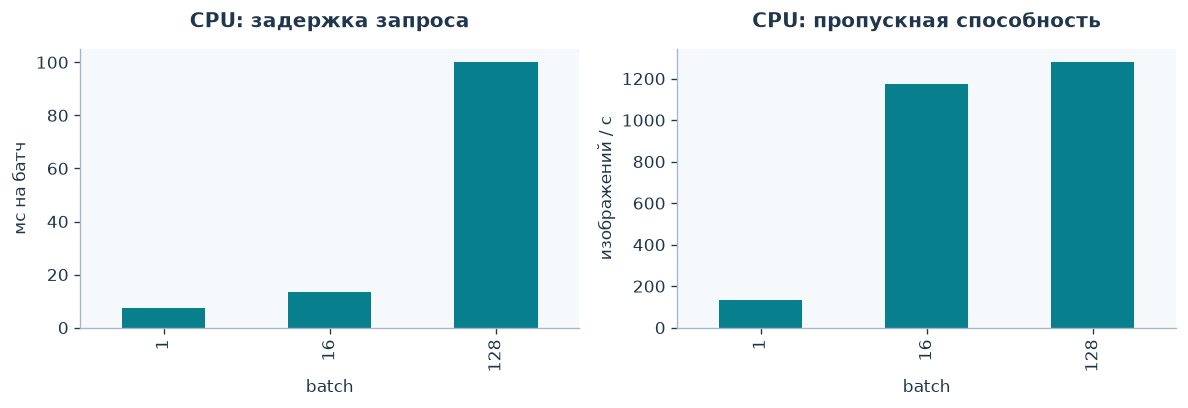

In [33]:
# Каждый столбец получен вашей inference_latency; числа не заданы заранее.
latency_rows = []
for size in [1, 16, 128]:
    batch_example = torch.zeros(size, 3, 32, 32)
    measured_ms = inference_latency(probe, batch_example, torch.device("cpu"), warmup=3, repeats=15)
    latency_rows.append({"batch": size, "latency_ms": measured_ms, "images_s": size * 1000 / measured_ms})
latency_frame = pd.DataFrame(latency_rows).set_index("batch")
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
latency_frame.latency_ms.plot.bar(ax=axes[0], ylabel="мс на батч", title="CPU: задержка запроса")
latency_frame.images_s.plot.bar(ax=axes[1], ylabel="изображений / с", title="CPU: пропускная способность")
figure.tight_layout()
plt.show()

## Готовые преобразования train и test

Функция возвращает `torchvision.transforms.v2.Compose`.
При `augment=True`: RandomCrop(32,padding=4,padding_mode="reflect"),
RandomHorizontalFlip(0.5), ColorJitter(brightness=0.3,contrast=0.3).
При обоих значениях: ToDtype(float32,scale=True), затем Normalize(mean,std).
Для validation/test случайных преобразований нет.
Порядок операций и диапазоны — часть контракта; mean/std передаются аргументами.

In [34]:
# mean, std: (3,), статистики RGB в [0,1]; вход transform - CHW uint8, выход CHW float32.
def build_transform(mean: np.ndarray, std: np.ndarray, augment: bool) -> v2.Compose:
    steps = []
    if augment:
        steps.extend([
            v2.RandomCrop(32, padding=4, padding_mode="reflect"),
            v2.RandomHorizontalFlip(0.5),
            v2.ColorJitter(brightness=0.3, contrast=0.3),
        ])
    steps.extend([v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean.tolist(), std.tolist())])
    transform = v2.Compose(steps)
    return transform

In [35]:
raw = torch.from_numpy(data["train_images"][0].copy()).permute(2, 0, 1)
plain_transform = build_transform(mean, std, False)
aug_transform = build_transform(mean, std, True)
assert torch.equal(plain_transform(raw), plain_transform(raw))
assert plain_transform(raw).dtype == torch.float32
aug_view = aug_transform(raw)
assert aug_view.shape == (3, 32, 32) and torch.isfinite(aug_view).all()

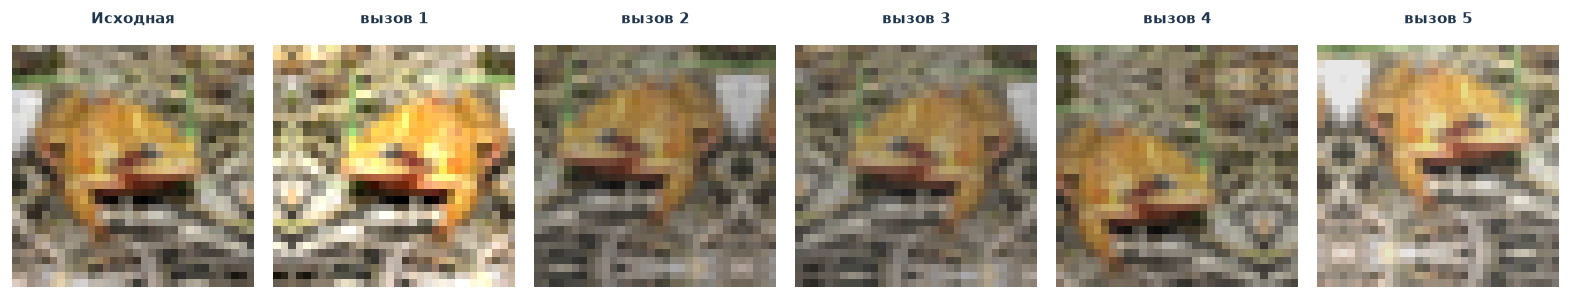

In [36]:
# Обратная нормализация нужна только для показа; модели подают нормализованный тензор.
visible_augmentations = [data["train_images"][0]]
for index in range(5):
    standardized = aug_transform(raw)
    restored = standardized * torch.tensor(std)[:, None, None] + torch.tensor(mean)[:, None, None]
    restored_rgb = restored.clamp(0, 1).permute(1, 2, 0).numpy()
    visible_augmentations.append(restored_rgb)
show_images(visible_augmentations, ["Исходная"] + [f"вызов {i}" for i in range(1, 6)])

## Обучение трех моделей

Ваша CNN использует собственные MaxPool, BatchNorm и Dropout. Готовая MLP имеет архитектуру 3072 → 512 → 256 → 10.
Во всех опытах Adam(lr=0.001,weight_decay=0), одинаковые эпохи и батч.
MLP и обычная CNN используют детерминированную нормализацию; третья модель отличается
от обычной CNN только аугментацией. Seed сбрасывают **до** создания каждой модели,
генератор порядка объектов создают заново. Для CNN начальные веса и порядок совпадают.

Функция ниже вызывает написанную `train_epoch`, а validation и возврат к лучшему
состоянию уже реализованы. Test не участвует в выборе эпохи.

In [37]:
class DenseNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10),
        )

    # images: float32 (N, 3, 32, 32); logits: (N, 10), без softmax.
    def forward(self, images: torch.Tensor) -> torch.Tensor:
        logits = self.layers(images)
        return logits

In [38]:
def fit_for_lab(model, train_loader, val_loader, optimizer, epochs, device):
    history = []
    best_loss = float("inf")
    best_state = None
    synchronize(device)
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        train_loss = train_epoch(model, train_loader, optimizer, device)
        probabilities = predict_probabilities(model, val_loader, device)
        metrics = quality_metrics(val_loader.dataset.labels.numpy(), probabilities)
        history.append({"epoch": epoch, "train_loss": train_loss,
                        "val_loss": metrics["log_loss"], "val_accuracy": metrics["accuracy"]})
        if metrics["log_loss"] < best_loss:
            best_loss = metrics["log_loss"]
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        print("эпоха", epoch, "validation accuracy", round(metrics["accuracy"], 4))
    model.load_state_dict(best_state)
    model.eval()
    synchronize(device)
    seconds = time.perf_counter() - started
    return history, seconds

эпоха 1 validation accuracy 0.4055
эпоха 2 validation accuracy 0.4145
эпоха 3 validation accuracy 0.44
эпоха 4 validation accuracy 0.4545
эпоха 5 validation accuracy 0.4525
эпоха 6 validation accuracy 0.453
эпоха 7 validation accuracy 0.4545
эпоха 8 validation accuracy 0.4525
эпоха 1 validation accuracy 0.4595
эпоха 2 validation accuracy 0.512
эпоха 3 validation accuracy 0.5625
эпоха 4 validation accuracy 0.604
эпоха 5 validation accuracy 0.5935
эпоха 6 validation accuracy 0.6115
эпоха 7 validation accuracy 0.6335
эпоха 8 validation accuracy 0.646
эпоха 1 validation accuracy 0.426
эпоха 2 validation accuracy 0.4895
эпоха 3 validation accuracy 0.525
эпоха 4 validation accuracy 0.56
эпоха 5 validation accuracy 0.543
эпоха 6 validation accuracy 0.586
эпоха 7 validation accuracy 0.602
эпоха 8 validation accuracy 0.5855


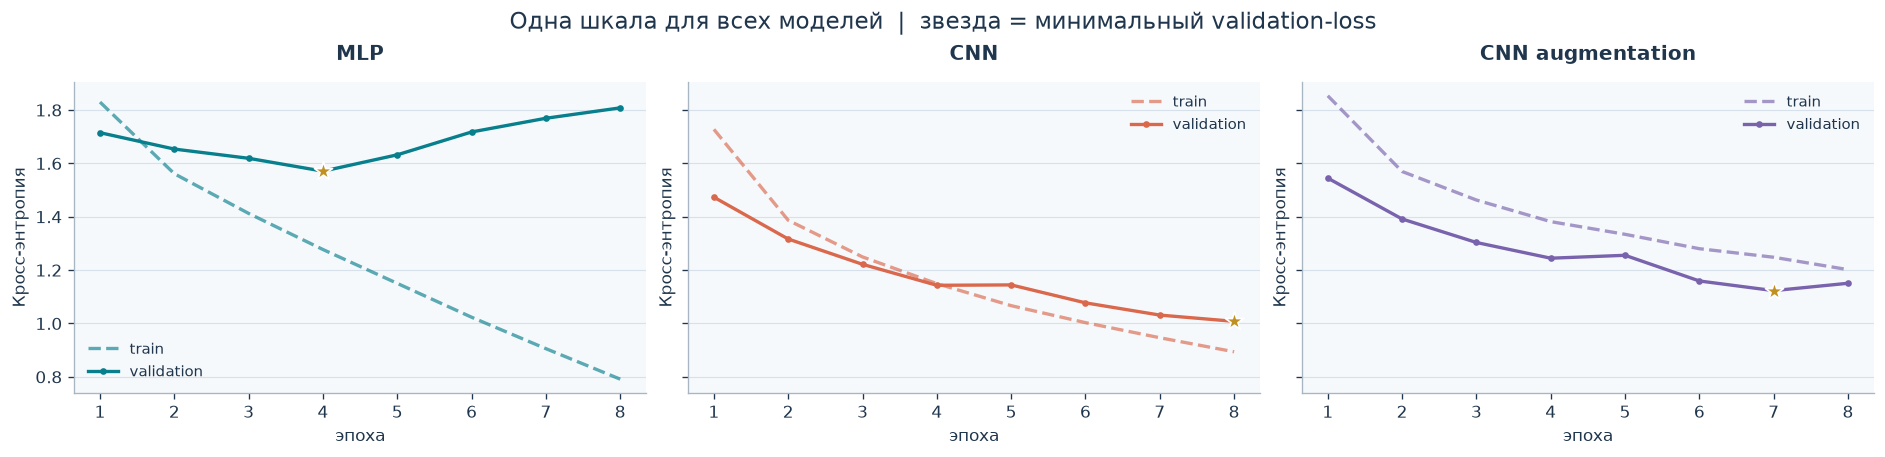

In [41]:
lab_runs = {}
for name, kind, augment in [("MLP", "mlp", False), ("CNN", "cnn", False), ("CNN augmentation", "cnn", True)]:
    seed_everything(SEED)
    model = DenseNet() if kind == "mlp" else ConvNet()
    model = model.to(DEVICE)
    dataset = ImageDataset(data["train_images"], data["train_labels"], mean, std)
    dataset.transform = build_transform(mean, std, augment)
    loader = make_loader(dataset, BATCH_SIZE, shuffle=True, seed=SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0)
    history, seconds = fit_for_lab(model, loader, val_loader, optimizer, EPOCHS, DEVICE)
    lab_runs[name] = {"model": model, "history": history, "train_s": seconds}
plot_histories({name: result["history"] for name, result in lab_runs.items()})

,accuracy,macro_f1,log_loss,balanced_accuracy,top3_accuracy,brier,parameters,train_s,batch1_ms,batch128_ms,images_s
model,,,,,,,,,,,
MLP,0.4745,0.4675,1.5419,0.4745,0.7815,0.6705,1707274,18.3481,0.1937,0.4252,301019.9402
CNN,0.6640,0.6610,0.9690,0.6640,0.9030,0.4639,156170,101.8081,21.3614,21.8042,5870.4301
CNN augmentation,0.6075,0.5988,1.1119,0.6075,0.8810,0.5228,156170,181.0461,21.1551,21.6028,5925.1499


,precision,recall,f1,support
самолет,0.6031,0.7750,0.6783,200
автомобиль,0.7477,0.8150,0.7799,200
птица,0.6176,0.5250,0.5676,200
кошка,0.4573,0.4550,0.4561,200
олень,0.6250,0.5250,0.5707,200
собака,0.6358,0.5150,0.5691,200
лягушка,0.7744,0.7550,0.7646,200
лошадь,0.6382,0.7850,0.7040,200
корабль,0.8202,0.7300,0.7725,200
грузовик,0.7343,0.7600,0.7469,200


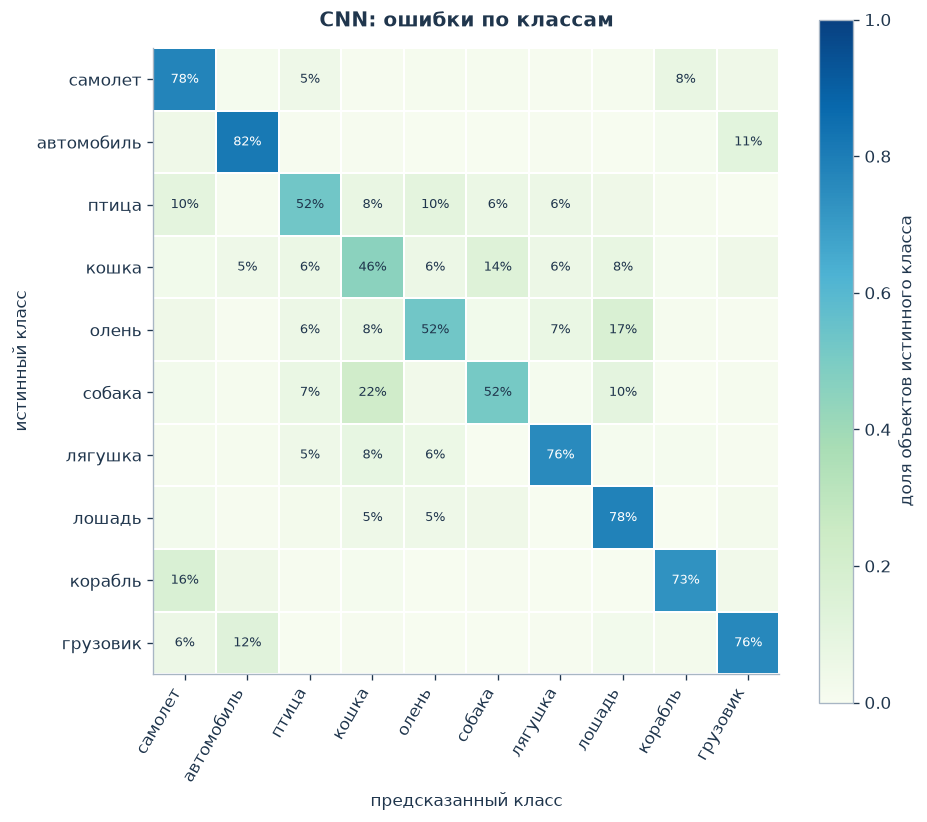

In [42]:
comparison_rows = []
for name, result in lab_runs.items():
    model = result["model"]
    probabilities = predict_probabilities(model, test_loader, DEVICE)
    row = quality_metrics(data["test_labels"], probabilities)
    extended_metrics = classification_metrics(data["test_labels"], probabilities)
    row.update({key: value for key, value in extended_metrics.items() if key not in row})
    images, _ = next(iter(test_loader))
    row.update({"model": name, "parameters": parameter_count(model), "train_s": result["train_s"],
                "batch1_ms": inference_latency(model, images[:1], DEVICE),
                "batch128_ms": inference_latency(model, images[:128], DEVICE)})
    row["images_s"] = len(images[:128]) / (row["batch128_ms"] / 1000)
    comparison_rows.append(row)
comparison_table = pd.DataFrame(comparison_rows).set_index("model")
show_table(comparison_table)
cnn_probabilities = predict_probabilities(lab_runs["CNN"]["model"], test_loader, DEVICE)
class_table = show_class_metrics(data["test_labels"], cnn_probabilities, "CNN: ошибки по классам")

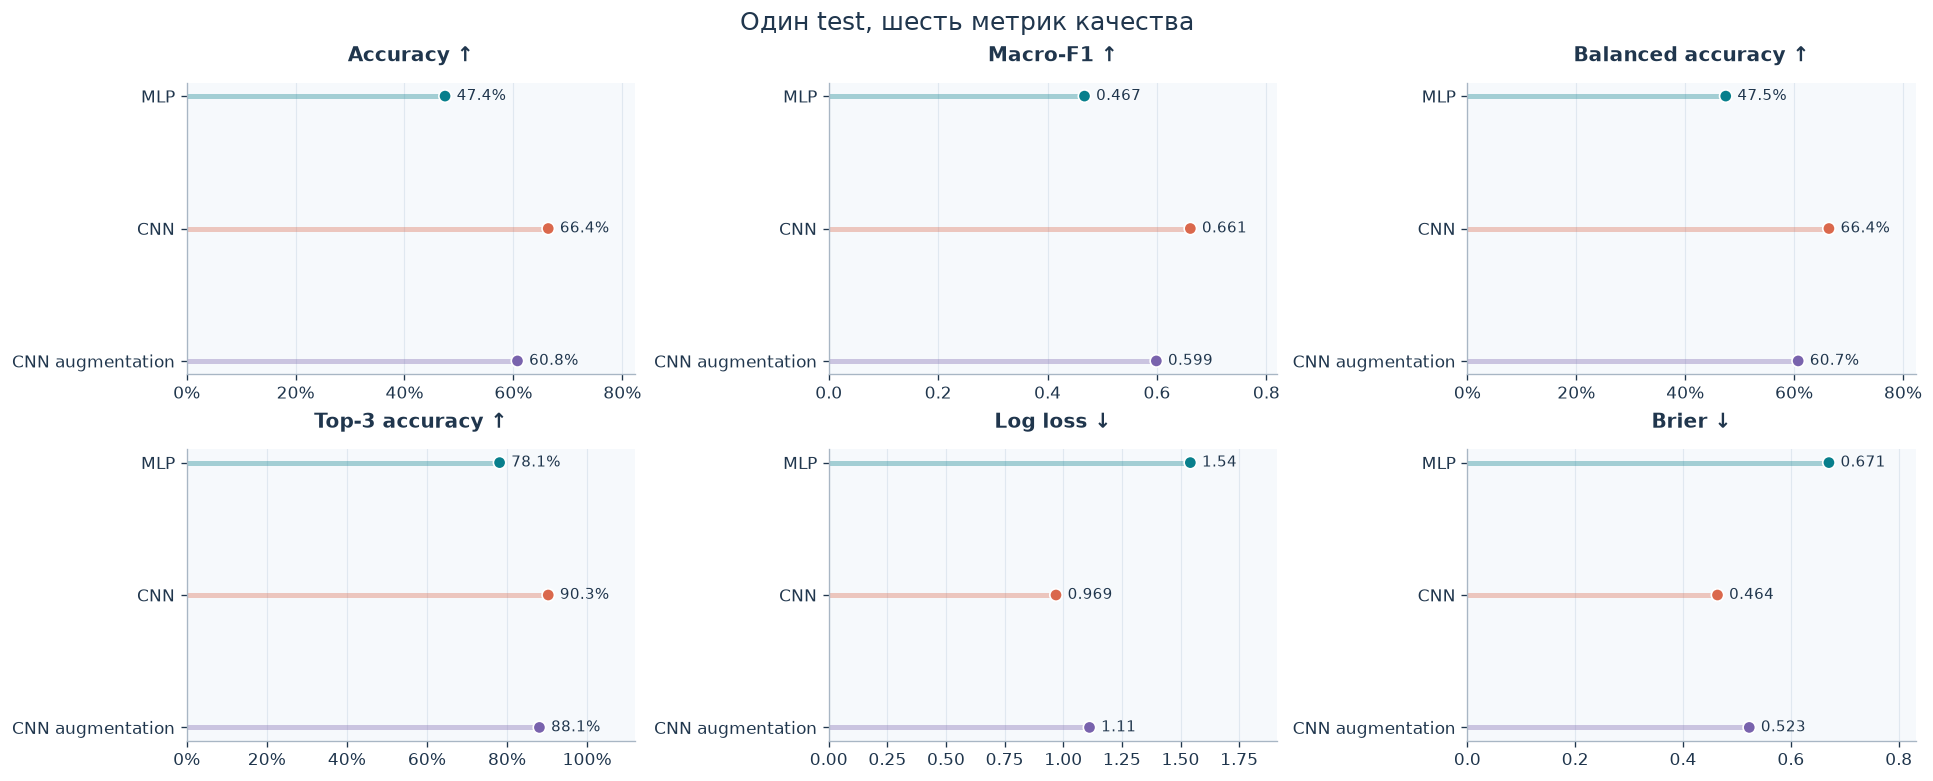

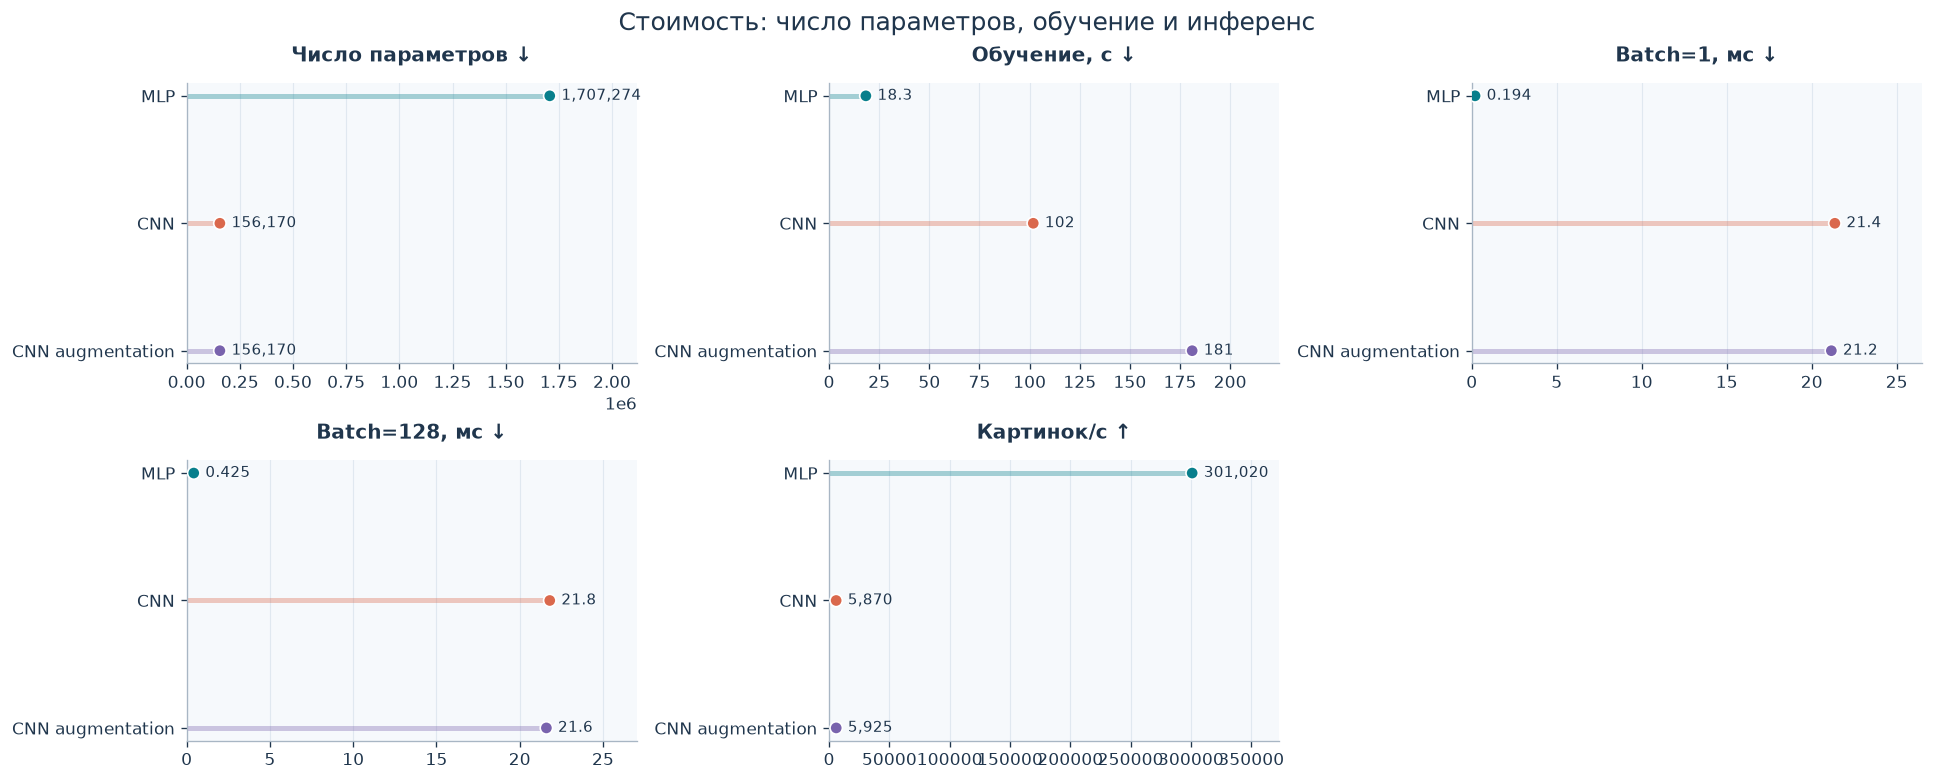

In [43]:
plot_metric_panels(comparison_table, title="Один test, шесть метрик качества")
plot_metric_panels(comparison_table, columns=["parameters", "train_s", "batch1_ms", "batch128_ms", "images_s"],
                   title="Стоимость: число параметров, обучение и инференс")

## Задача 9. Сравнение моделей в разных условиях — 1 балл

Нужно составить таблицу: **как каждая обученная модель решает задачу на каждом варианте тестовых данных**. Например, сравнить обычную CNN и CNN с аугментациями на чистых и зашумлённых картинках. Повторно обучать модели в этой функции не нужно.

### Что передаётся в функцию

`models` — словарь «название → обученная модель PyTorch». `loaders` — словарь «условие → DataLoader». Например:

```python
models = {"CNN": cnn, "CNN + aug": cnn_aug}
loaders = {"clean": clean_loader, "noise_1": noisy_loader}
```

`clean_loader` содержит чистые тестовые картинки, `noisy_loader` — картинки с фиксированным шумом. В каждом loader используется `ImageDataset` и `shuffle=False`. Метки данного набора лежат в `loader.dataset.labels` — это одномерный Tensor длины N. Порядок меток совпадает с порядком выдачи картинок. Не следует брать метки из глобальной переменной: для каждого loader источник меток указан отдельно.

`device` — устройство, на котором уже находятся модели. Передайте его готовой функции получения предсказаний.

### Что уже реализовано

`predict_probabilities(model, loader, device)` возвращает NumPy-массив **N×10**: строка соответствует картинке, столбец — классу. Функция сама включает `eval()` и отключает запись графа производных. Используйте её для получения предсказаний.

Написанная вами `quality_metrics(labels, probabilities)` получает метки как NumPy-массив **(N,)** и вероятности **(N,10)**. Она возвращает словарь из трёх чисел: `accuracy`, `macro_f1`, `log_loss`.

### Что должна вернуть evaluate_conditions

Для **каждой пары** «модель, условие» вычислить три метрики на соответствующих предсказаниях и метках. Вернуть один DataFrame с колонками в следующем порядке:

| Столбец | Содержимое |
|:--|:--|
| `model` | название модели из ключей models |
| `condition` | название условия из ключей loaders |
| `accuracy` | доля верных ответов этой модели на этом наборе |
| `macro_f1` | macro-F1 той же пары модель/набор |
| `log_loss` | log loss по вероятностям той же пары |

Для примера выше нужны **четыре строки**. Числа ниже условные и показывают только устройство результата:

| model | condition | accuracy | macro_f1 | log_loss |
|:--|:--|--:|--:|--:|
| CNN | clean | 0.70 | 0.69 | 0.90 |
| CNN | noise_1 | 0.52 | 0.50 | 1.40 |
| CNN + aug | clean | 0.68 | 0.67 | 0.95 |
| CNN + aug | noise_1 | 0.59 | 0.57 | 1.20 |

Порядок строк произвольный. Число строк равно `len(models) * len(loaders)`; повторяющихся пар быть не должно. Не усреднять метрики разных условий и не подставлять общие предсказания для разных моделей.

В эксперименте ниже две модели и 13 условий: чистые данные и по три силы сдвига, затемнения, шума и размытия. Поэтому ожидается **26 строк**. Искажения одинаковые для обеих моделей; их параметры не подбирают по test. Случаи отсутствия выигрыша аугментаций также сохраняют в отчёте.

In [44]:
def evaluate_conditions(models: dict[str, nn.Module], loaders: dict[str, DataLoader], device: torch.device) -> pd.DataFrame:
    columns = ["model", "condition", "accuracy", "macro_f1", "log_loss"]
    rows = []
    for model_name, model in models.items():
        for condition_name, loader in loaders.items():
            probabilities = predict_probabilities(model, loader, device)
            labels = torch.as_tensor(loader.dataset.labels).cpu().numpy()
            metrics = quality_metrics(labels, probabilities)
            rows.append({"model": model_name, "condition": condition_name, **metrics})
    return pd.DataFrame(rows, columns=columns)

In [45]:
condition_loaders = {"clean": test_loader}
for kind in ["shift", "brightness", "noise", "blur"]:
    for severity in [1, 2, 3]:
        changed = corrupt_images(data["test_images"], kind, severity, seed=123)
        dataset = ImageDataset(changed, data["test_labels"], mean, std)
        condition_loaders[f"{kind}_{severity}"] = make_loader(dataset)
models = {name: lab_runs[name]["model"] for name in ["CNN", "CNN augmentation"]}
robustness_table = evaluate_conditions(models, condition_loaders, DEVICE)
assert len(robustness_table) == 26
assert set(robustness_table.columns) == {"model", "condition", "accuracy", "macro_f1", "log_loss"}
assert not robustness_table.duplicated(["model", "condition"]).any()
show_table(robustness_table)
gains = robustness_table.pivot(index="condition", columns="model", values="accuracy")
gains["accuracy_gain"] = gains["CNN augmentation"] - gains["CNN"]
show_table(gains)

,model,condition,accuracy,macro_f1,log_loss
0,CNN,clean,0.6640,0.6610,0.9690
1,CNN,shift_1,0.6200,0.6183,1.1035
2,CNN,shift_2,0.5090,0.5081,1.3972
3,CNN,shift_3,0.3965,0.3910,1.8197
4,CNN,brightness_1,0.6520,0.6521,0.9836
5,CNN,brightness_2,0.5920,0.5999,1.1632
6,CNN,brightness_3,0.3615,0.3631,1.8208
7,CNN,noise_1,0.5745,0.5617,1.1867
8,CNN,noise_2,0.3875,0.3520,1.8518
9,CNN,noise_3,0.2715,0.2166,2.5891


model,CNN,CNN augmentation,accuracy_gain
condition,,,
blur_1,0.6230,0.5575,-0.0655
blur_2,0.3885,0.3675,-0.0210
blur_3,0.3380,0.3280,-0.0100
brightness_1,0.6520,0.6025,-0.0495
brightness_2,0.5920,0.5715,-0.0205
brightness_3,0.3615,0.4555,0.0940
clean,0.6640,0.6075,-0.0565
noise_1,0.5745,0.5360,-0.0385
noise_2,0.3875,0.3830,-0.0045


### Отделяем тип искажения от его силы

Не соединяем разные типы искажений общей ломаной. В каждой панели меняется только сила одного воздействия; точка 0 — тот же чистый test. Общая вертикальная шкала позволяет сравнить устойчивость к разным воздействиям. Macro-F1 оценивает решения по классам, log loss — вероятности истинных классов.

Сначала найдите падение от 0 до 3 внутри каждой модели. Затем сравните модели при **одинаковых типе и силе** искажения. Это две разные разности.

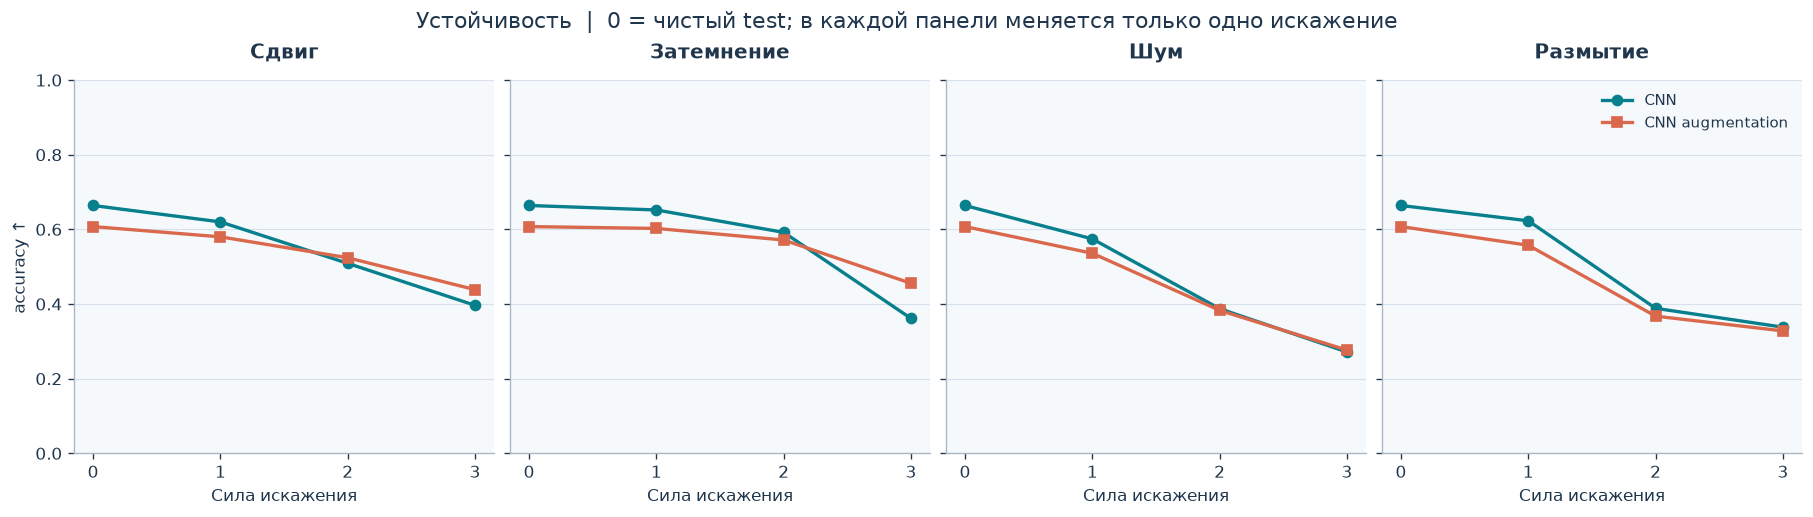

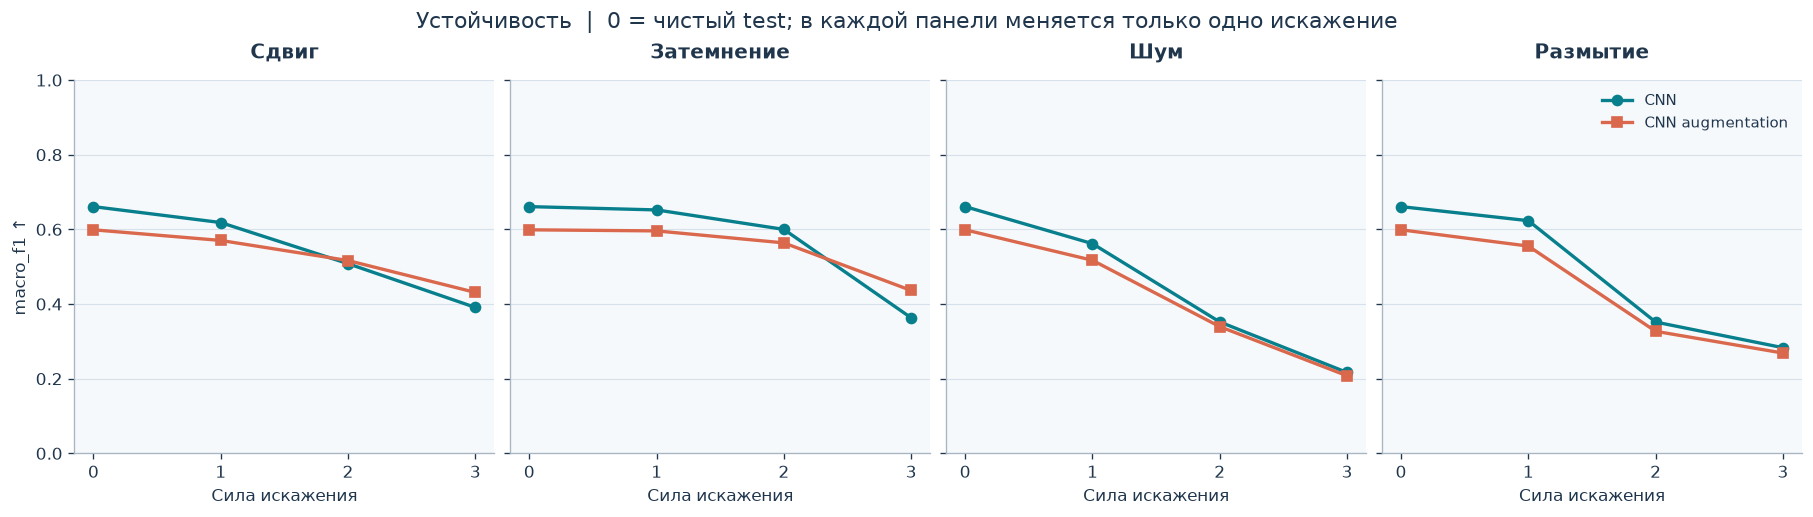

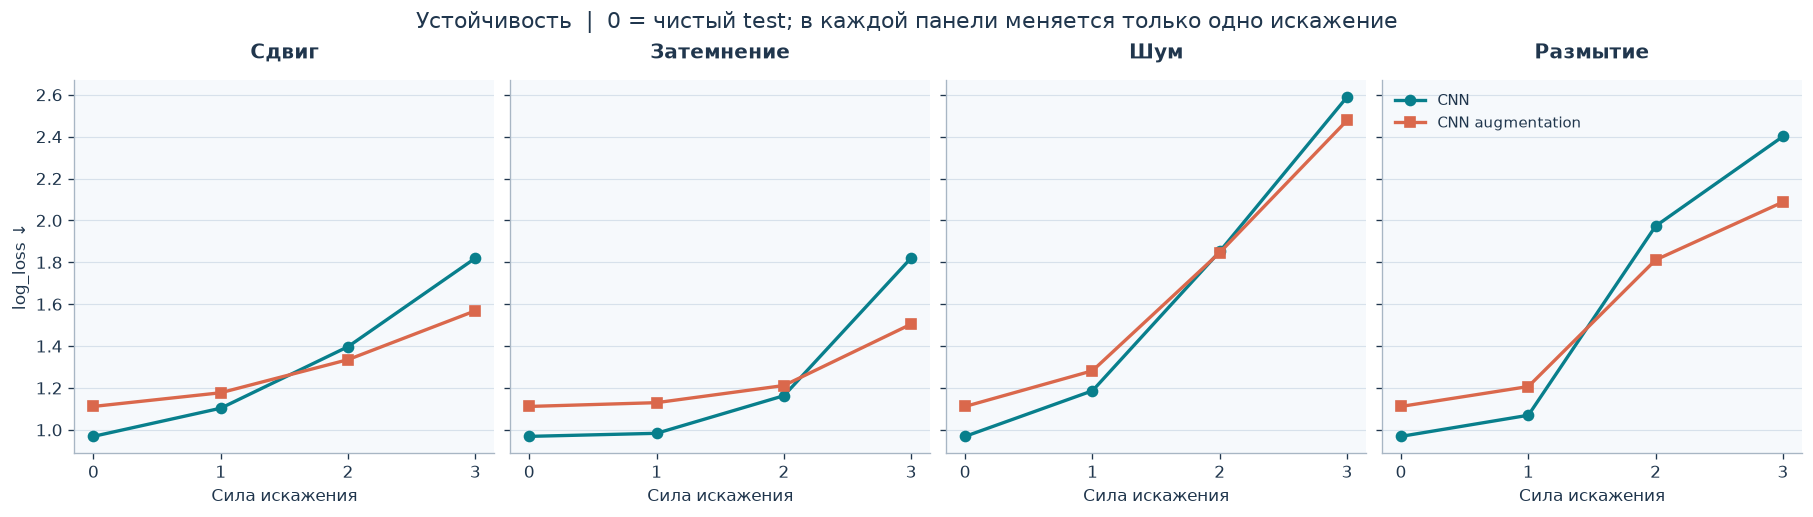

In [46]:
from support.lesson11_visuals import plot_corruption_facets

plot_corruption_facets(robustness_table, metric="accuracy")
plot_corruption_facets(robustness_table, metric="macro_f1")
plot_corruption_facets(robustness_table, metric="log_loss");

In [50]:
def pct(value):
    return f"{100 * value:.1f}%"

lines = []
lines.append(f"**Режим и устройство.** {'Полный' if FULL else 'Учебный'} режим: {TRAIN_SIZE} / {VAL_SIZE} / {TEST_SIZE} "
             f"объектов train / validation / test, {EPOCHS} эпох, батч {BATCH_SIZE}, seed {SEED}, устройство {DEVICE}.")

lines.append("**Качество и стоимость.**")
for name, row in comparison_table.iterrows():
    lines.append(f"- {name}: accuracy {pct(row['accuracy'])}, macro-F1 {row['macro_f1']:.3f}, log loss {row['log_loss']:.3f}; "
                 f"параметров {int(row['parameters']):,}; обучение {row['train_s']:.1f} с; "
                 f"batch=1: {row['batch1_ms']:.2f} мс; batch=128: {row['batch128_ms']:.2f} мс ({row['images_s']:.0f} картинок/с).")
best_accuracy = comparison_table["accuracy"].idxmax()
best_loss = comparison_table["log_loss"].idxmin()
lines.append(f"Лучшая accuracy у «{best_accuracy}», наименьший log loss у «{best_loss}»"
             + ("." if best_accuracy == best_loss else ": порядок моделей зависит от метрики."))
if {"MLP", "CNN"} <= set(comparison_table.index):
    ratio = comparison_table.loc["MLP", "parameters"] / comparison_table.loc["CNN", "parameters"]
    difference = 100 * (comparison_table.loc["CNN", "accuracy"] - comparison_table.loc["MLP", "accuracy"])
    lines.append(f"CNN имеет в {ratio:.1f} раза меньше параметров, чем MLP, и отличается по accuracy на {difference:+.1f} п.п.")

recall = recall_score(data["test_labels"], cnn_probabilities.argmax(axis=1), labels=np.arange(10), average=None, zero_division=0)
weakest = np.argsort(recall)[:3]
lines.append("**Ошибки по классам (CNN).** Наименьший recall: "
             + ", ".join(f"{CLASSES[index]} ({pct(recall[index])})" for index in weakest)
             + f". Наибольший: {CLASSES[int(np.argmax(recall))]} ({pct(recall.max())}).")

accuracy_wide = robustness_table.pivot(index="condition", columns="model", values="accuracy")
lines.append("**Аугментации и искажения** (accuracy: CNN → CNN augmentation, разность в п.п.).")
clean = accuracy_wide.loc["clean"]
lines.append(f"- Чистые изображения: {pct(clean['CNN'])} → {pct(clean['CNN augmentation'])}, "
             f"разность {100 * (clean['CNN augmentation'] - clean['CNN']):+.1f}.")
for kind in ["shift", "brightness", "noise", "blur"]:
    parts = []
    for severity in [1, 2, 3]:
        row = accuracy_wide.loc[f"{kind}_{severity}"]
        parts.append(f"сила {severity}: {pct(row['CNN'])} → {pct(row['CNN augmentation'])} ({100 * (row['CNN augmentation'] - row['CNN']):+.1f})")
    drop_plain = 100 * (clean["CNN"] - accuracy_wide.loc[f"{kind}_3", "CNN"])
    drop_aug = 100 * (clean["CNN augmentation"] - accuracy_wide.loc[f"{kind}_3", "CNN augmentation"])
    lines.append(f"- {kind}: " + "; ".join(parts) + f". Падение от чистых до силы 3: CNN {drop_plain:.1f}, CNN augmentation {drop_aug:.1f} п.п.")
gain_by_kind = {kind: float(np.mean([accuracy_wide.loc[f"{kind}_{s}", "CNN augmentation"] - accuracy_wide.loc[f"{kind}_{s}", "CNN"] for s in [1, 2, 3]])) * 100
                for kind in ["shift", "brightness", "noise", "blur"]}
positive = [kind for kind, value in gain_by_kind.items() if value > 0]
negative = [kind for kind, value in gain_by_kind.items() if value <= 0]
lines.append("В среднем по трём силам аугментации помогли для: " + (", ".join(positive) if positive else "ни одного семейства")
             + "; не помогли для: " + (", ".join(negative) if negative else "—") + ".")

lines.append("**Скорость NumPy-свёрток** (медиана, ускорение относительно трёх циклов): "
             + "; ".join(f"{name} — {row['Медиана, мс']:.3f} мс (x{row['Ускорение к 3 циклам']:.1f})" for name, row in speed_table.iterrows()) + ".")
display(Markdown("\n\n".join(lines)))

**Режим и устройство.** Учебный режим: 12000 / 2000 / 2000 объектов train / validation / test, 8 эпох, батч 128, seed 42, устройство cuda.

**Качество и стоимость.**

- MLP: accuracy 47.4%, macro-F1 0.467, log loss 1.542; параметров 1,707,274; обучение 18.3 с; batch=1: 0.19 мс; batch=128: 0.43 мс (301020 картинок/с).

- CNN: accuracy 66.4%, macro-F1 0.661, log loss 0.969; параметров 156,170; обучение 101.8 с; batch=1: 21.36 мс; batch=128: 21.80 мс (5870 картинок/с).

- CNN augmentation: accuracy 60.8%, macro-F1 0.599, log loss 1.112; параметров 156,170; обучение 181.0 с; batch=1: 21.16 мс; batch=128: 21.60 мс (5925 картинок/с).

Лучшая accuracy у «CNN», наименьший log loss у «CNN».

CNN имеет в 10.9 раза меньше параметров, чем MLP, и отличается по accuracy на +19.0 п.п.

**Ошибки по классам (CNN).** Наименьший recall: кошка (45.5%), собака (51.5%), олень (52.5%). Наибольший: автомобиль (81.5%).

**Аугментации и искажения** (accuracy: CNN → CNN augmentation, разность в п.п.).

- Чистые изображения: 66.4% → 60.8%, разность -5.6.

- shift: сила 1: 62.0% → 58.0% (-4.0); сила 2: 50.9% → 52.4% (+1.5); сила 3: 39.6% → 43.9% (+4.2). Падение от чистых до силы 3: CNN 26.8, CNN augmentation 16.9 п.п.

- brightness: сила 1: 65.2% → 60.2% (-4.9); сила 2: 59.2% → 57.1% (-2.0); сила 3: 36.1% → 45.6% (+9.4). Падение от чистых до силы 3: CNN 30.3, CNN augmentation 15.2 п.п.

- noise: сила 1: 57.5% → 53.6% (-3.8); сила 2: 38.8% → 38.3% (-0.5); сила 3: 27.2% → 27.7% (+0.5). Падение от чистых до силы 3: CNN 39.2, CNN augmentation 33.1 п.п.

- blur: сила 1: 62.3% → 55.8% (-6.6); сила 2: 38.9% → 36.8% (-2.1); сила 3: 33.8% → 32.8% (-1.0). Падение от чистых до силы 3: CNN 32.6, CNN augmentation 28.0 п.п.

В среднем по трём силам аугментации помогли для: shift, brightness; не помогли для: noise, blur.

**Скорость NumPy-свёрток** (медиана, ускорение относительно трёх циклов): 3 цикла — 24.842 мс (x1.0); 2 цикла — 4.875 мс (x5.1).

## Вывод по эксперименту

Заполнить текстовую ячейку ниже. Указать режим, устройство и число эпох; сравнить
число параметров, время обучения, batch=1 и batch=128, accuracy, macro-F1 и log loss.
Назвать классы с низким recall. Для каждого семейства искажений привести хотя бы
одну пару accuracy и разность; отдельно отметить чистые изображения.
Объяснить ограничения одного seed и синтетических искажений. Положительный выигрыш
аугментаций не является условием сдачи; отсутствие выигрыша требует такого же
честного обсуждения. Автоматические баллы проверяют код девяти обязательных задач и двух бонусных реализаций;
содержательный вывод преподаватель обсуждает отдельно.

Отдельно привести измеренное ускорение заполненных NumPy-реализаций и объяснить режимы своих слоёв: какие величины меняются в train, какие сохраняются и что происходит в eval.

Режим и устройство: Учебный режим: 12000 / 2000 / 2000 объектов train / validation / test, 8 эпох, батч 128, seed 42, устройство cuda.

Качество и стоимость MLP/CNN:
| Модель | Параметры | Обучение, с | batch=1, мс | batch=128, мс | accuracy | macro-F1 | log loss |
|---|---|---|---|---|---|---|---|
| MLP | 1 707 274 | 18.3 | 0.19 | 0.43 | 0.4745 | 0.4675 | 1.542 |
| CNN | 156 170 | 101.8 | 21.36 | 21.80 | 0.6640 | 0.6610 | 0.969 |
| CNN augmentation | 156 170 | 181.0 | 21.16 | 21.60 | 0.6075 | 0.5988 | 1.112 |

Ошибки по классам: Наименьший recall у классов «кошка» (45.5%), «собака» (51.5%), «олень» (52.5%); у «птицы» тоже 52.5%. Это визуально похожие друг на друга животные на мелких 32×32 картинках, и сеть с 8 эпохами обучения их плохо различает. Наибольший recall у «автомобиля» (81.5%), далее «лошадь» (78.5%) и «самолёт» (77.5%) по recall, а по F1 лучшие «автомобиль» (0.78), «корабль» (0.77) и «лягушка» (0.76). Транспортные классы в целом распознаются лучше животных.

Аугментации и искажения:
| condition | CNN | CNN augmentation | accuracy_gain |
|---|---:|---:|---:|
| blur_1 | 0.6230 | 0.5575 | -0.0655 |
| blur_2 | 0.3885 | 0.3675 | -0.0210 |
| blur_3 | 0.3380 | 0.3280 | -0.0100 |
| brightness_1 | 0.6520 | 0.6025 | -0.0495 |
| brightness_2 | 0.5920 | 0.5715 | -0.0205 |
| brightness_3 | 0.3615 | 0.4555 | 0.0940 |
| clean | 0.6640 | 0.6075 | -0.0565 |
| noise_1 | 0.5745 | 0.5360 | -0.0385 |
| noise_2 | 0.3875 | 0.3830 | -0.0045 |
| noise_3 | 0.2715 | 0.2765 | 0.0050 |
| shift_1 | 0.6200 | 0.5800 | -0.0400 |
| shift_2 | 0.5090 | 0.5240 | 0.0150 |
| shift_3 | 0.3965 | 0.4385 | 0.0420 |


Ограничения вывода: Так как всё запускалось на одном сиде, то доверять небольшим изменениям метрик нельзя - это может быть статистической погрешностью.

**Скорость NumPy-свёрток.** Медиана: три цикла — 24.84 мс, два цикла — 4.87 мс, ускорение ×5.1.

**Режимы слоёв.**
- `ManualDropout`: в train случайная маска зануляет долю p активаций, оставшиеся умножаются на 1/(1−p), чтобы сохранить среднее значение; маска каждый раз новая. В eval слой возвращает вход без изменений.
- `ManualBatchNorm2d`: в train нормализация идёт по статистикам текущего батча (среднее и дисперсия по (N, H, W) для каждого канала), при этом обновляются сохраняемые буферы `running_mean`, `running_var` (по экспоненциальному среднему с momentum 0.1, дисперсия с поправкой Бесселя `count/(count−1)`) и счётчик `num_batches_tracked`. Обучаемые `weight` и `bias` меняются оптимизатором. В eval используются накопленные `running_mean` и `running_var`, буферы не обновляются, результат не зависит от остальных объектов батча (поэтому batch=1 в eval допустим, а в train нужно больше одного значения на канал).
- `ManualMaxPool2d` и NumPy-свёртка от режима не зависят: у них нет случайности и нет накапливаемого состояния.